# 🚦 Crashscape: US Traffic Accident Patterns & Hotspots

**Prodigy InfoTech Data Science Internship – Task 05** · Vaishnav Kumbhar ([@VaishnavK9](https://github.com/VaishnavK9))

> *Analyze traffic accident data to identify patterns related to road conditions, weather and time of day. Visualize accident hotspots and contributing factors.*

**Data:** [US Accidents (2016 – Mar 2023)](https://www.kaggle.com/datasets/sobhanmoosavi/us-accidents), about **7.7 million** accidents across 49 states, collected from traffic APIs by Moosavi et al.

**Story in this notebook**
1. Load 3 GB of CSV memory-efficiently and clean it
2. A data caveat that shapes everything: *reporting drift*
3. **When:** time of day, week and year
4. **Weather:** what conditions accidents happen in, and how severe they get
5. **Road conditions:** junctions, signals, crossings and road type
6. **Where:** states, cities and ~1 km hotspots
7. **Why:** a gradient-boosting model + SHAP for contributing factors
8. **Key findings & safety recommendations**

> ℹ️ **Severity (1–4)** in this dataset measures the accident's *impact on traffic* (length of the delay), **not** injuries. "Severe" below means Severity ≥ 3.

In [1]:
import json
import sys
import tempfile
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, Markdown, display

from src import analysis, config, hotspots, viz
from src.data_loader import load_parquet, report_memory

# Charts drawn here go to a temp folder so the committed reports/figures/ stay exactly as
# produced by `python -m src.viz` / `src.hotspots` / `src.factors`.
FIGURES = ROOT / "reports" / "figures"
config.FIGURES_DIR = Path(tempfile.mkdtemp(prefix="crashscape_nb_"))

pd.set_option("display.precision", 2)
pd.set_option("display.width", 140)
viz.set_style()

def show(path, width=900):
    """Display a saved figure inline."""
    display(Image(filename=str(path), width=width))

## 1 · Loading 3 GB efficiently

The raw CSV is never loaded in one go. `src/data_loader.py` streams it **straight from the zip** in 1M-row chunks:
- reads only the **33 columns** we need (`usecols`)
- uses compact dtypes (`float32`, `int8`, `boolean`, `category`)
- writes a single zstd-compressed **Parquet** file (238 MB)

`src/cleaning.py` then:
- parses the mixed timestamp formats (`format="mixed"`)
- derives time features
- buckets 145 weather strings into 8 groups
- imputes weather readings by State × month
- classifies roads as Interstate / Highway / Local

A reproducible **500k-row sample** (stratified by State × Severity, `random_state=42`) powers the model and the dashboard.

Here we load the full cleaned table, with only the columns we need:

In [2]:
df = load_parquet(config.CLEAN_PARQUET, columns=analysis.ANALYSIS_COLUMNS + ["road_type", "Start_Lat", "Start_Lng", "Street"])
print(f"{len(df):,} accidents · {df['State'].nunique()} states · "
      f"{df['year'].min()}–{df['year'].max()}")
df.dtypes.value_counts()

[accidents_clean.parquet] 7,728,394 rows × 34 cols | memory: 405.0 MB
7,728,394 accidents · 49 states · 2016–2023


bool        16
float32      5
int8         3
int16        1
category     1
category     1
category     1
category     1
category     1
category     1
category     1
category     1
category     1
Name: count, dtype: int64

In [3]:
# What the cleaning produced: weather buckets and road types
pd.concat({
    "weather_bucket %": df["weather_bucket"].value_counts(normalize=True).mul(100),
    "road_type %": df["road_type"].value_counts(normalize=True).mul(100),
}, axis=1).round(1)

,weather_bucket %,road_type %
Clear,43.6,NaN
Cloudy,40.4,NaN
Rain,6.6,NaN
Fog,2.6,NaN
Snow,2.3,NaN
Other,2.3,NaN
Thunderstorm,1.1,NaN
Windy,1.0,NaN
Local road,NaN,47.5
Highway,NaN,27.5


## 2 · A caveat that shapes everything: reporting drift

Before comparing severity across conditions, check that severity is labelled consistently over time. **It isn't.**

In [4]:
tables = analysis.run_all(df, save=False)
tables["by_year"][["year", "accidents", "high_severity_pct", "partial_year"]]

,year,accidents,high_severity_pct,partial_year
0,2016,410821,34.22,False
1,2017,718093,35.56,False
2,2018,893426,35.65,False
3,2019,954303,27.87,False
4,2020,1178913,18.36,False
5,2021,1563753,11.45,False
6,2022,1762452,6.88,False
7,2023,246633,2.86,True


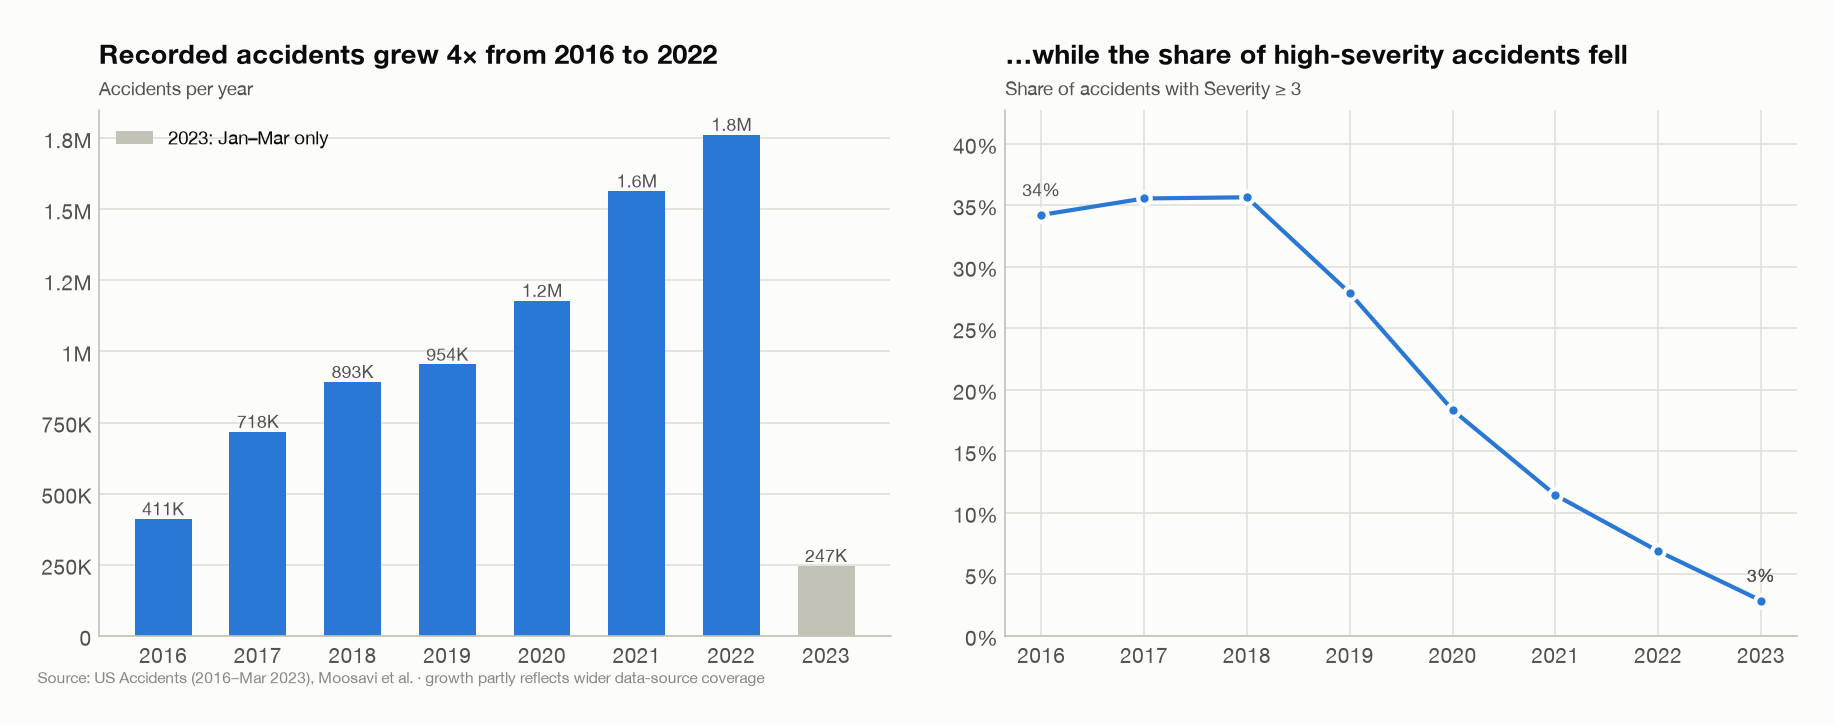

In [5]:
show(viz.plot_year_trend(tables['by_year']))

Recorded accidents grew **4.3×** from 2016 to 2022 as more data sources came online. Over the same period the share of Severity ≥ 3 accidents fell from **~35% to ~7%**. Roads did not get five times safer; the sources and their labelling changed. Precipitation readings are also ~90% missing before 2019.

**What we do about it:**
- Wherever we compare severity across conditions, we use a **year-adjusted rate**: each group's observed rate is divided by the rate its year mix predicts, then rescaled to the overall rate.
- The model includes year and state as *controls*, so the effects of road, weather and time are measured net of the drift.

## 3 · When do accidents happen?

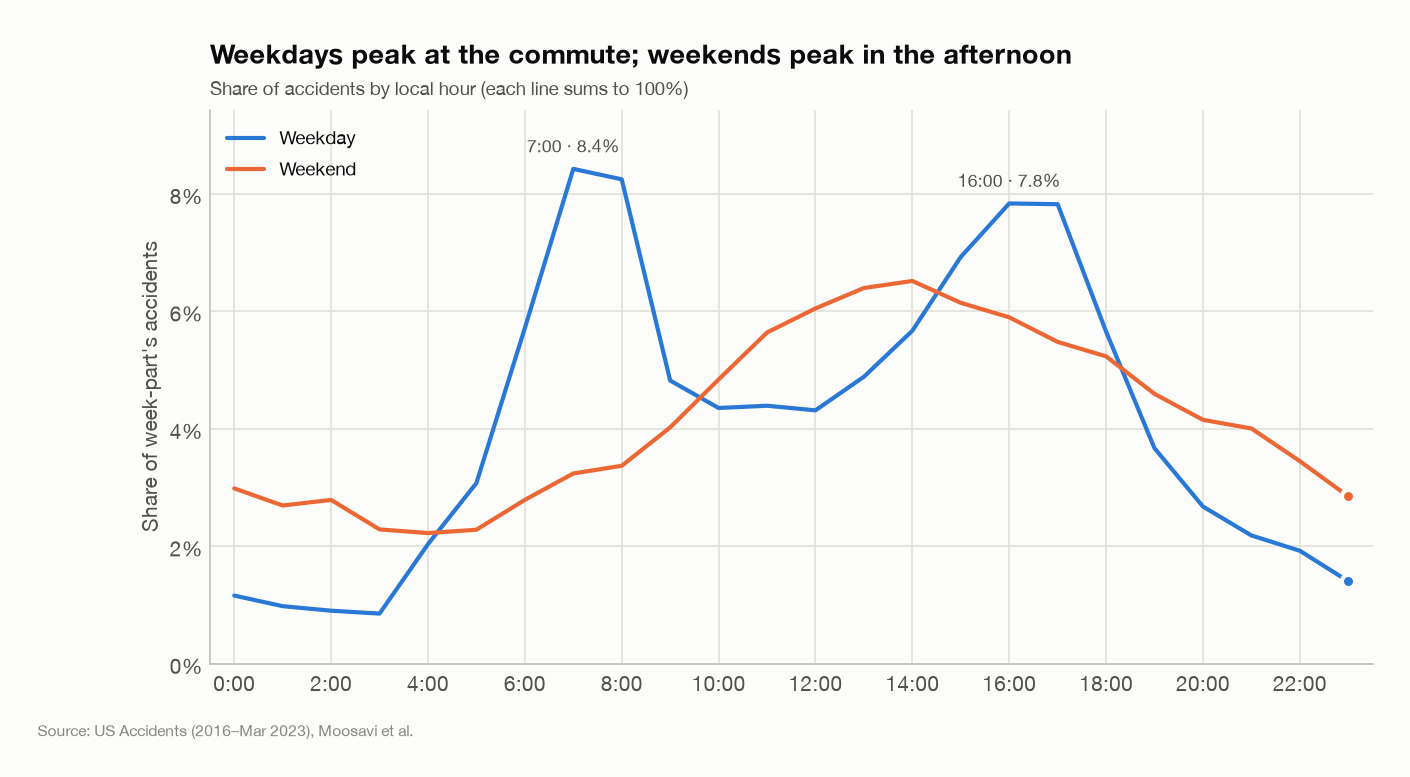

In [6]:
show(viz.plot_hourly(tables['by_hour_weekpart']))

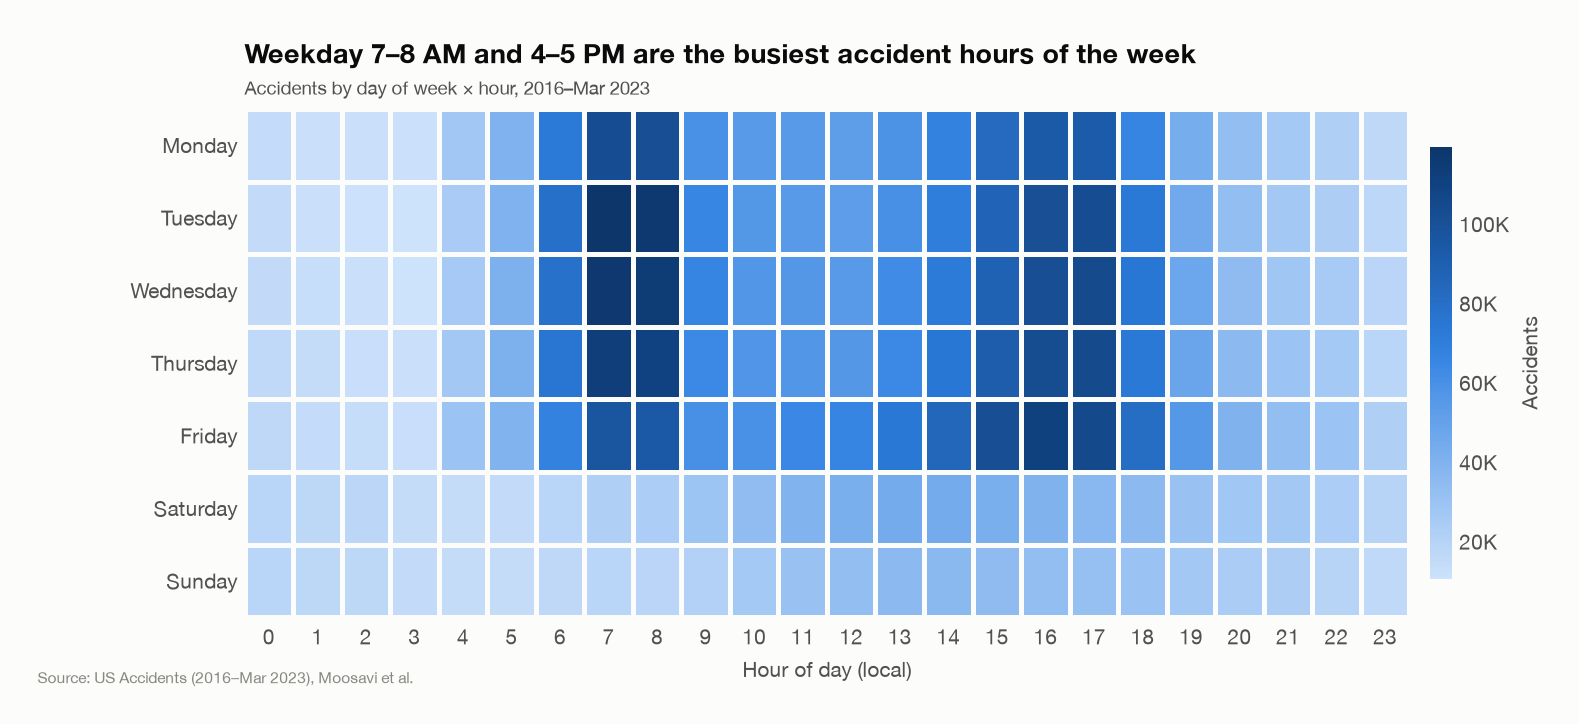

In [7]:
show(viz.plot_hour_dow_heatmap(tables['hour_dow_matrix']), width=1000)

,accidents,high_severity_pct,high_severity_adj_pct
day_of_week,,,
Monday,1210921,19.30,18.47
Tuesday,1290929,19.01,18.24
Wednesday,1312389,18.87,18.31
Thursday,1316229,18.97,18.57
Friday,1366499,19.14,18.94
Saturday,668683,20.99,25.08
Sunday,562744,22.33,26.17


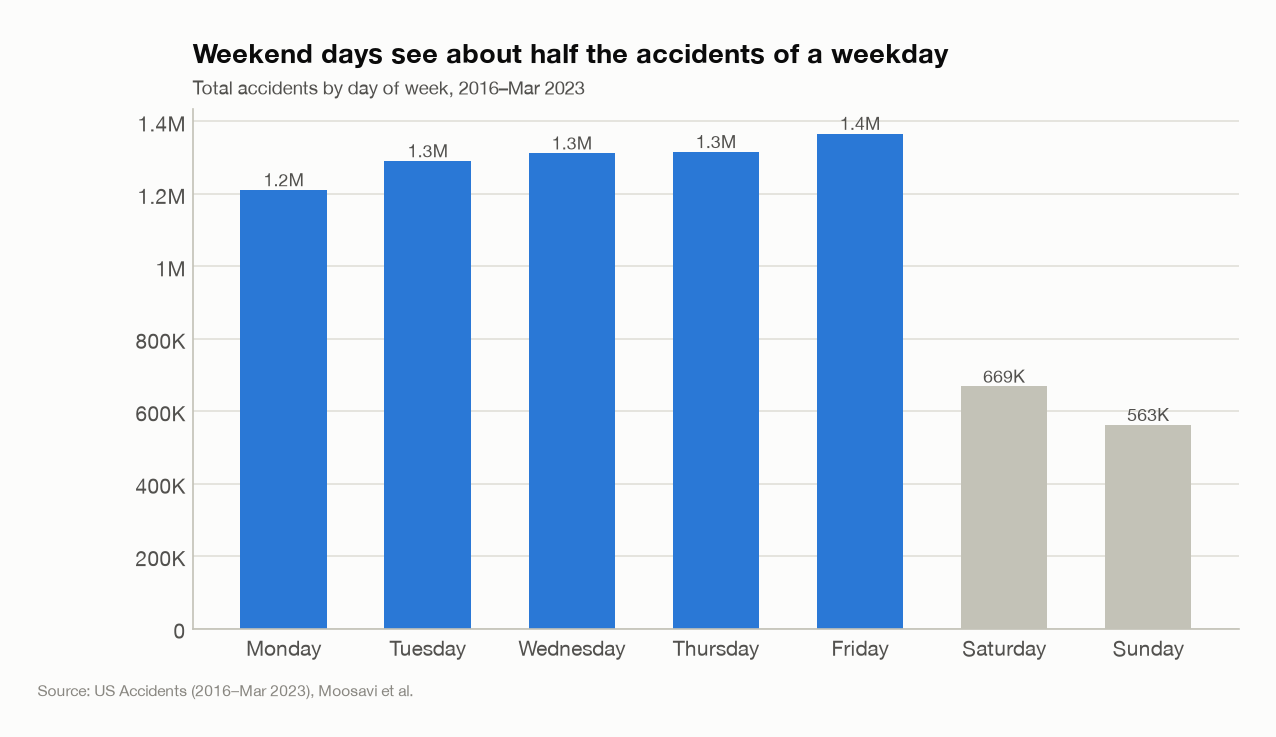

In [8]:
t = tables["by_day_of_week"].set_index("day_of_week")
display(t[["accidents", "high_severity_pct", "high_severity_adj_pct"]])
show(viz.plot_day_of_week(tables["by_day_of_week"]), width=750)

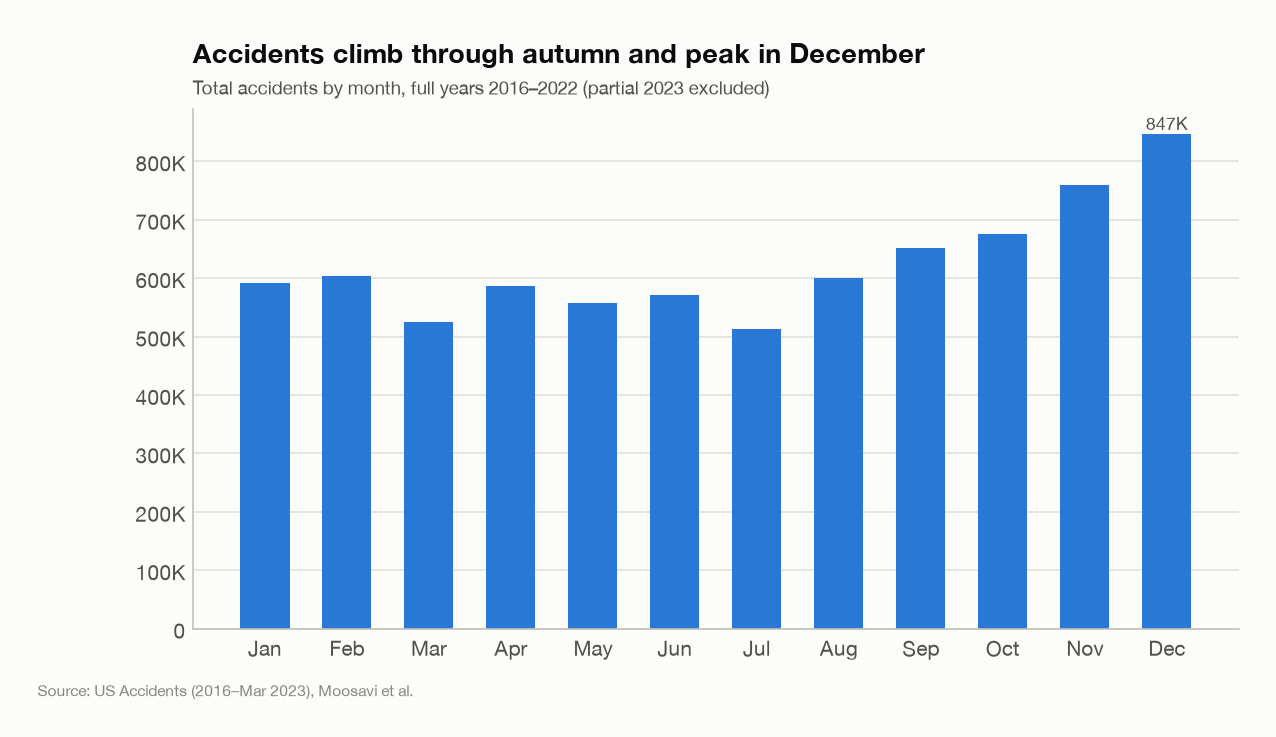

In [9]:
show(viz.plot_month(tables['by_month']), width=750)

**Takeaways**
- **Weekdays follow the commute.** 8.4% of weekday accidents happen 7–8 AM, with a second peak at 4–5 PM. The busiest cells in the whole week are Tuesday–Thursday at 7–8 AM.
- **Weekends peak mid-afternoon (2 PM)** and have roughly half the accidents of a weekday. Per accident, though, weekend crashes are *more* often severe (about 21–22% vs 19%, raw).
- **Accidents climb through autumn and peak in December**, likely from shorter days, holiday travel and winter weather.

## 4 · Weather: frequency vs severity

In [10]:
w = tables["by_weather"][["weather_bucket", "accidents", "share_pct", "high_severity_pct", "high_severity_adj_pct"]]
w

,weather_bucket,accidents,share_pct,high_severity_pct,high_severity_adj_pct
0,Clear,3369545,43.60,16.95,18.00
1,Cloudy,3119944,40.37,21.74,20.03
2,Rain,512097,6.63,23.06,22.69
3,Fog,203165,2.63,16.19,16.82
4,Snow,178748,2.31,19.88,23.70
5,Other,176711,2.29,21.53,21.58
6,Thunderstorm,88606,1.15,21.03,25.23
7,Windy,79578,1.03,14.28,21.64


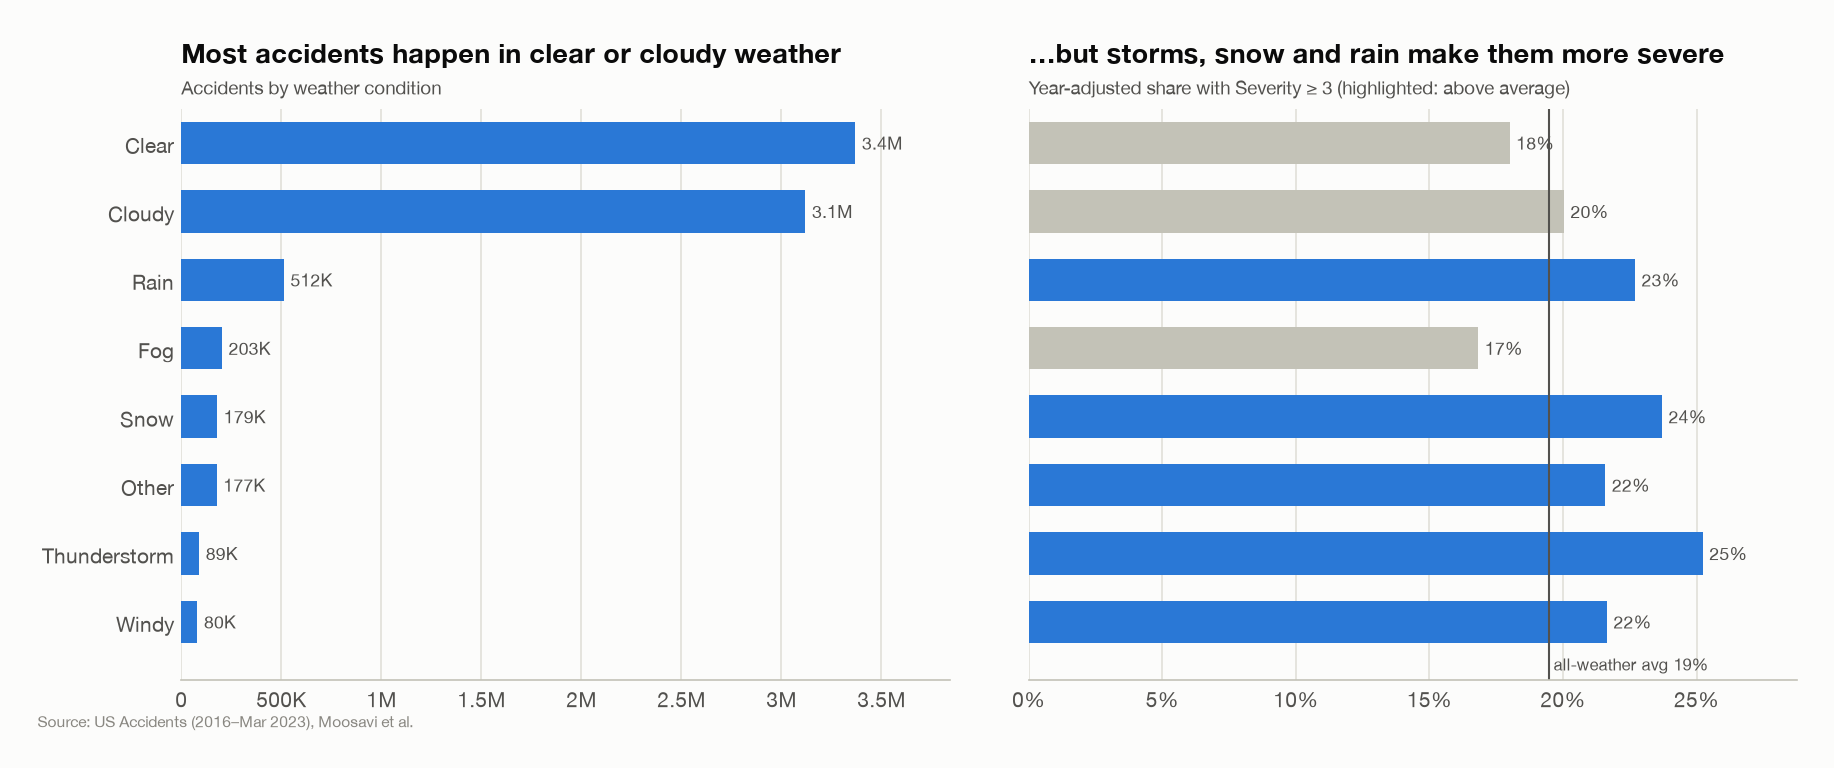

In [11]:
show(viz.plot_weather(tables['by_weather']), width=1000)

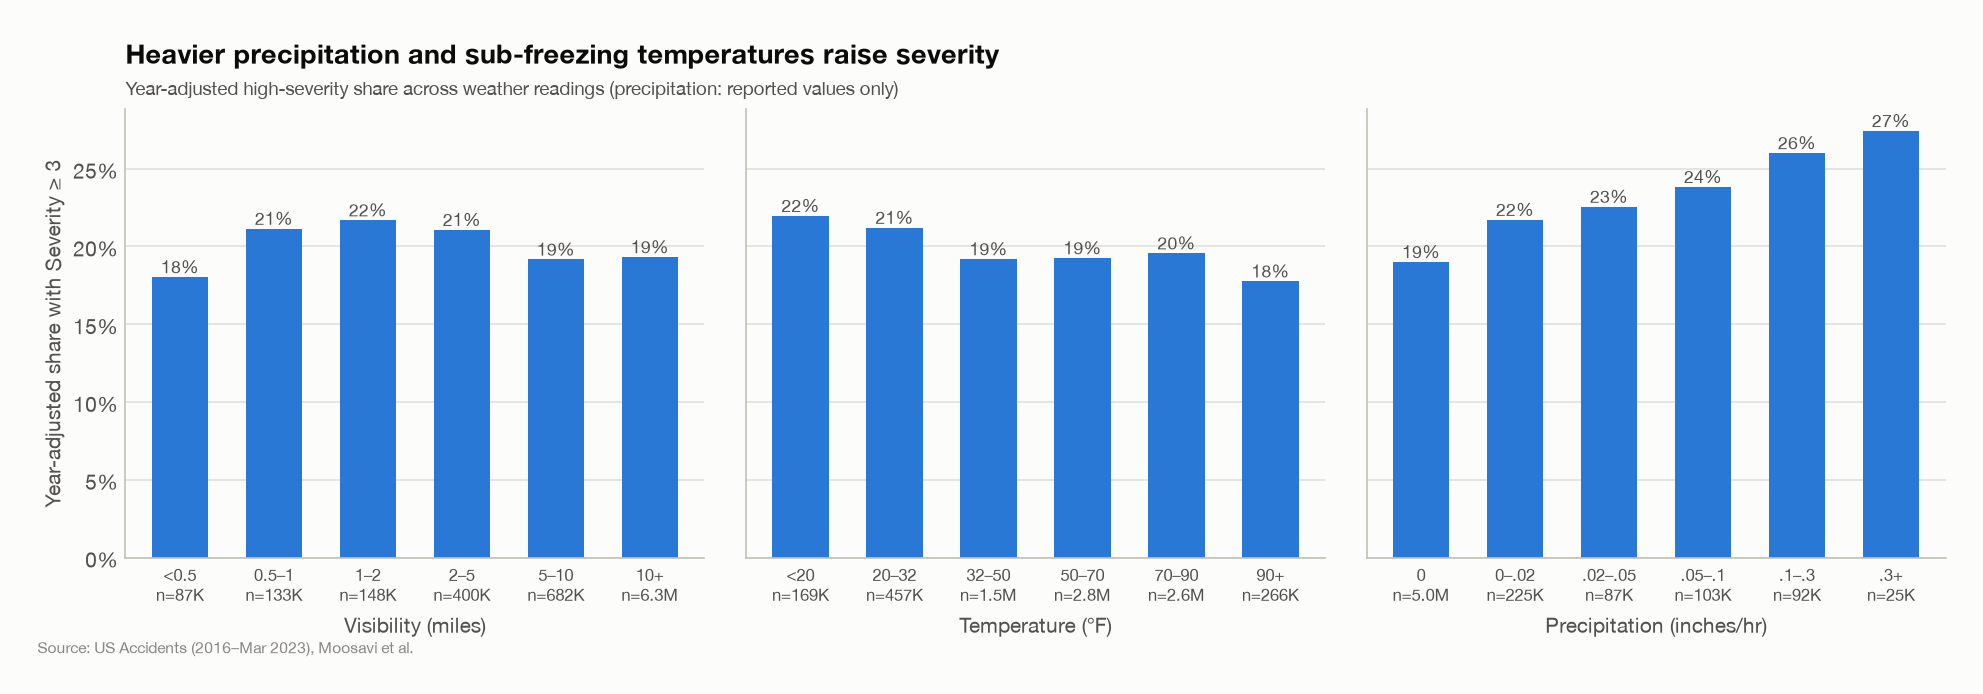

In [12]:
show(viz.plot_weather_numeric_rates(tables['numeric_bins_vs_severity']), width=1000)

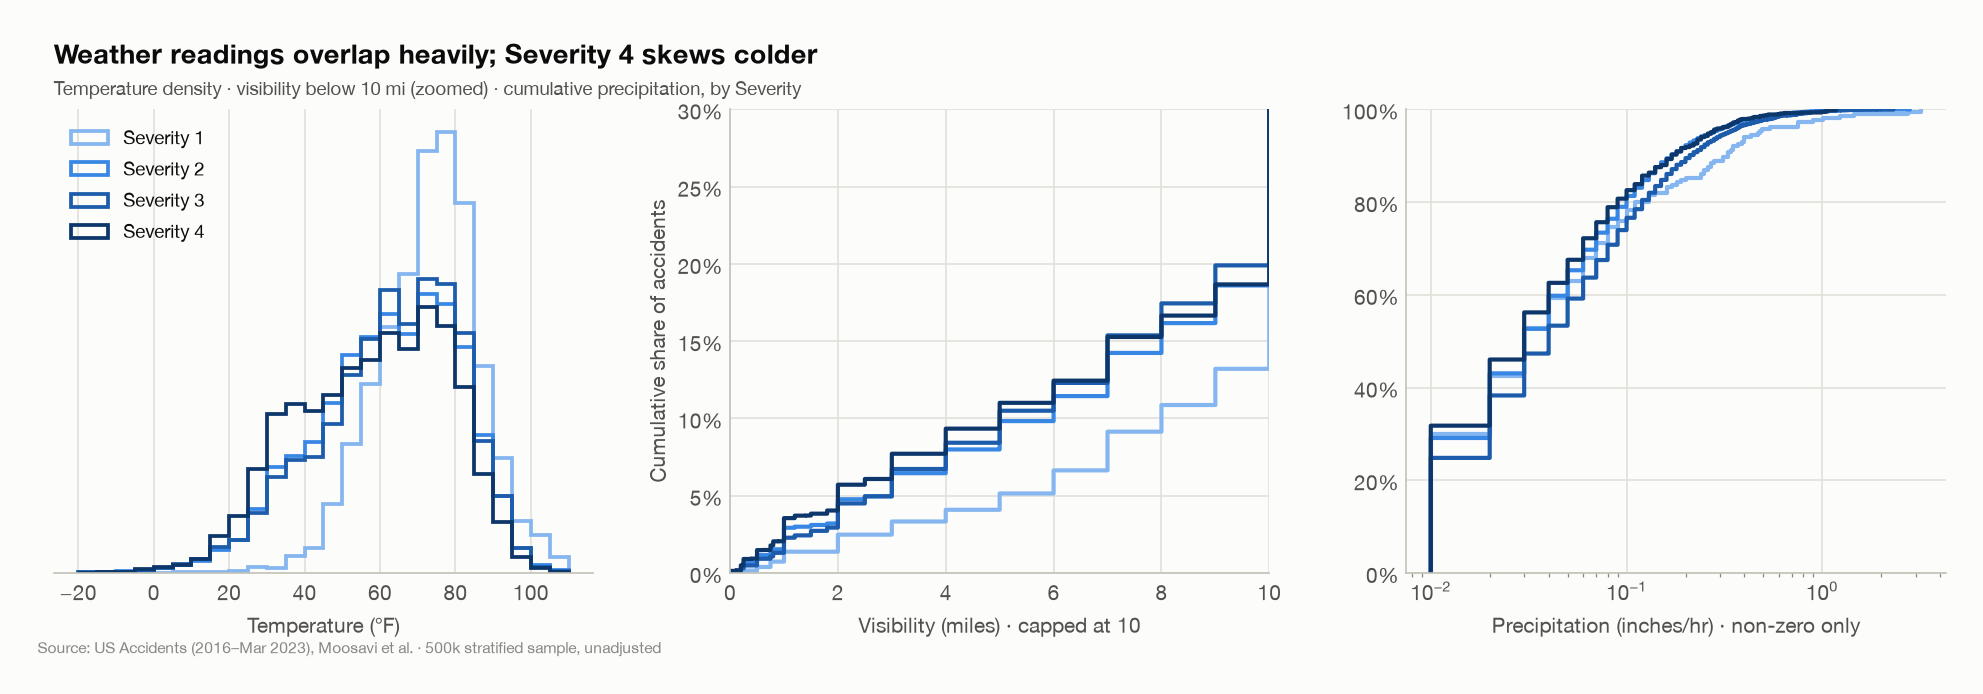

In [13]:
sample = load_parquet(config.SAMPLE_PARQUET, columns=analysis.ANALYSIS_COLUMNS, verbose=False)
show(viz.plot_weather_distributions(sample), width=1000)

**Takeaways**
- **84% of accidents happen in clear or cloudy weather.** Most crashes are about traffic volume, not weather.
- When bad weather *does* hit, accidents are worse. Year-adjusted severe share:
  - **thunderstorms 25%**, **snow 24%**, **rain 23%**
  - versus **clear 18%** and **fog 17%**
- **Precipitation has a dose-response:** the severe share rises steadily from **19% with none to 27% above 0.3 in/hr**.
- Temperature and visibility distributions overlap heavily across severity levels. Their raw effect is small, and §7 shows most of it disappears once *where and when* is known.

## 5 · Road conditions

In [14]:
r = tables["road_features"][["feature", "accidents", "share_pct", "high_sev_adj_pct_with", "high_sev_adj_pct_without", "severity_lift_adj_pts"]]
r

,feature,accidents,share_pct,high_sev_adj_pct_with,high_sev_adj_pct_without,severity_lift_adj_pts
0,Traffic_Signal,1143772,1.48e+01,8.02,21.89,-13.87
1,Crossing,873763,1.13e+01,6.48,21.28,-14.79
2,Junction,571342,7.39e+00,24.94,18.99,5.95
3,Stop,214371,2.77e+00,6.12,19.85,-13.73
4,Station,201901,2.61e+00,7.48,19.78,-12.30
5,Amenity,96334,1.25e+00,5.92,19.64,-13.73
6,Railway,66979,8.67e-01,14.23,19.51,-5.28
7,Give_Way,36582,4.73e-01,14.30,19.49,-5.19
8,No_Exit,19545,2.53e-01,11.19,19.48,-8.29
9,Traffic_Calming,7598,9.83e-02,13.25,19.47,-6.22


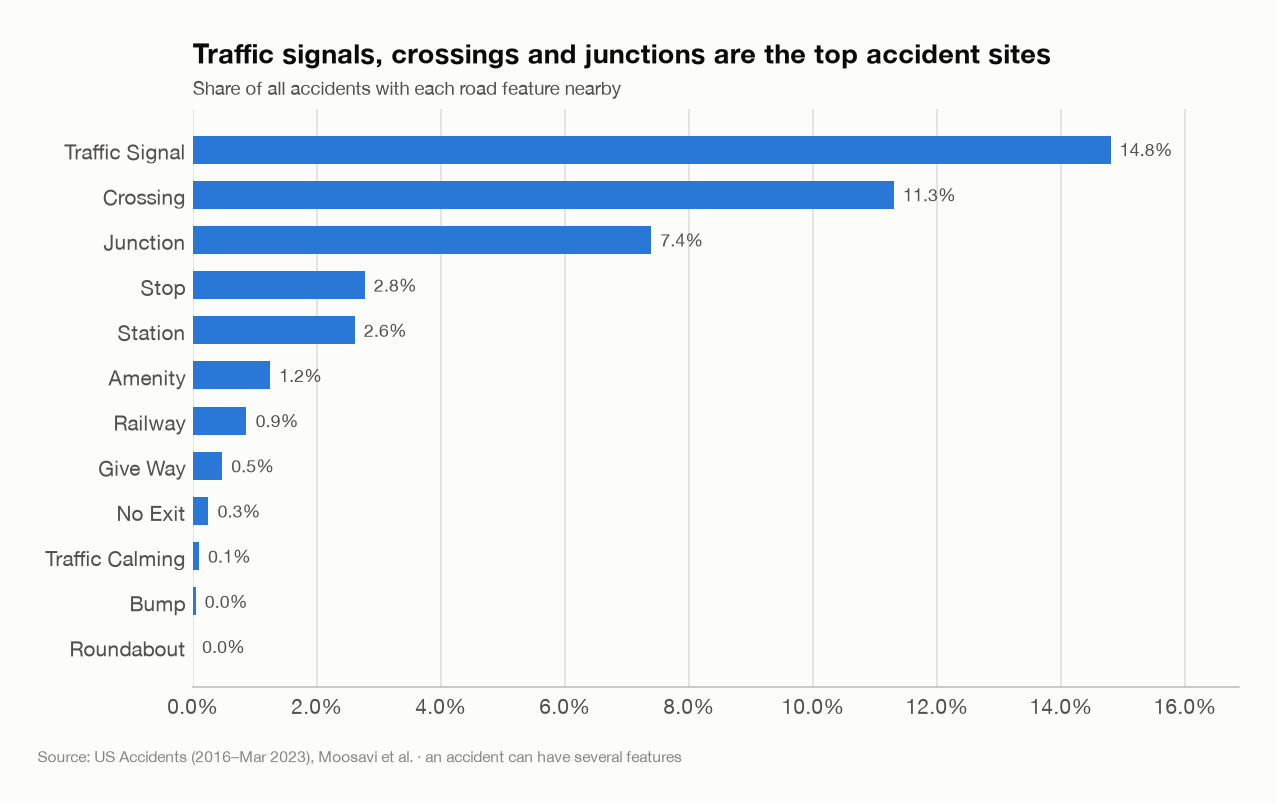

In [15]:
show(viz.plot_road_share(tables['road_features']), width=750)

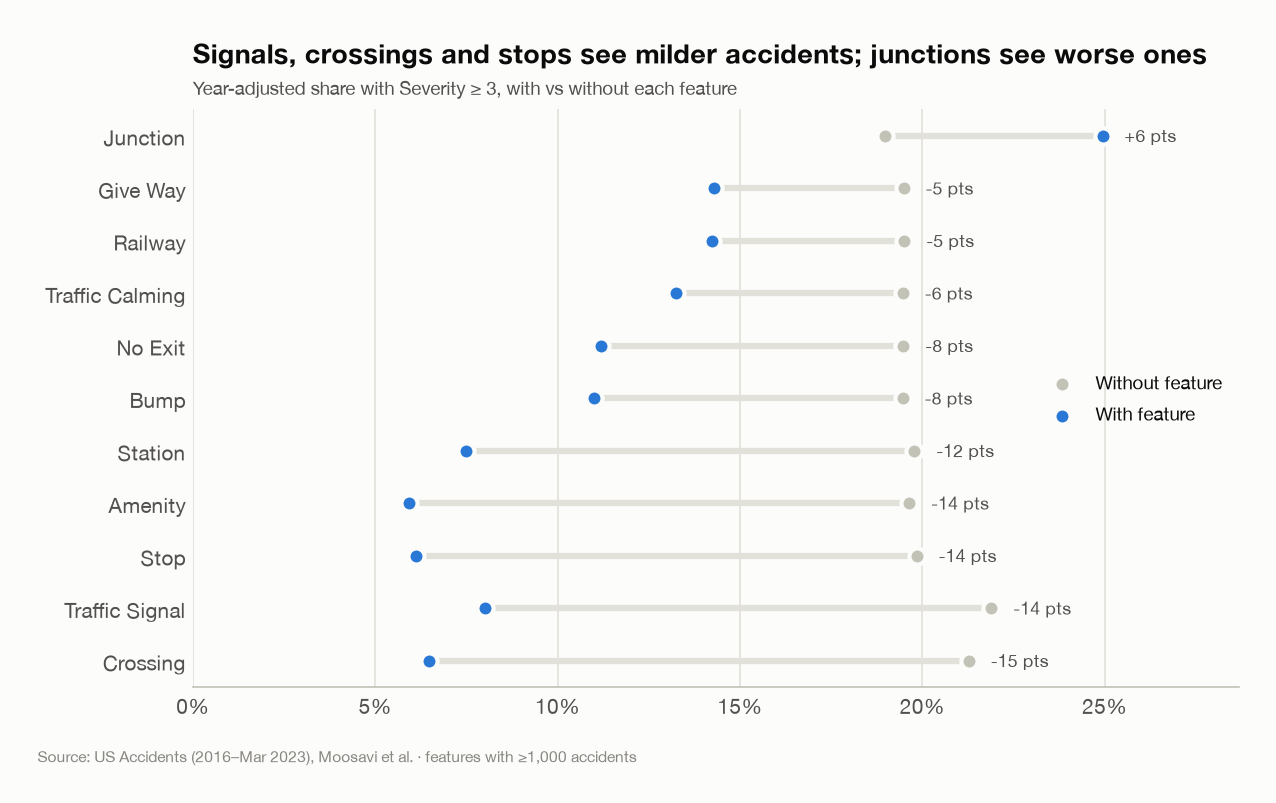

In [16]:
show(viz.plot_road_severity(tables['road_features']), width=800)

In [17]:
# Road type (derived from the street name), year-adjusted
analysis.add_year_baseline(df)
rt = analysis._severity_summary(df.groupby("road_type", observed=True)).reset_index()
rt["share_pct"] = rt["accidents"] / rt["accidents"].sum() * 100
rt

,road_type,accidents,avg_severity,high_severity_pct,high_severity_adj_pct,share_pct
0,Interstate,1936477,2.38,35.99,37.55,25.06
1,Highway,2123177,2.22,18.96,18.78,27.47
2,Local road,3668740,2.12,11.03,10.85,47.47


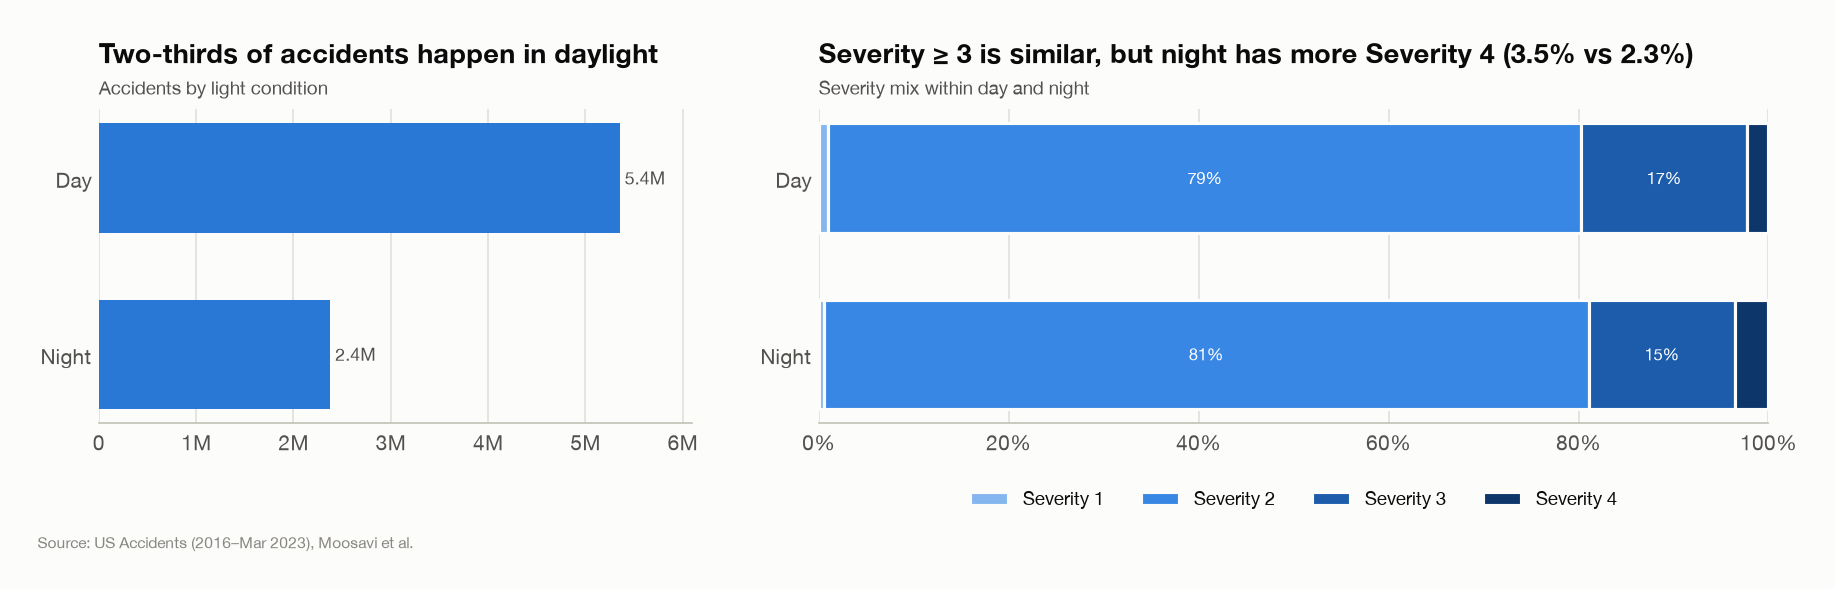

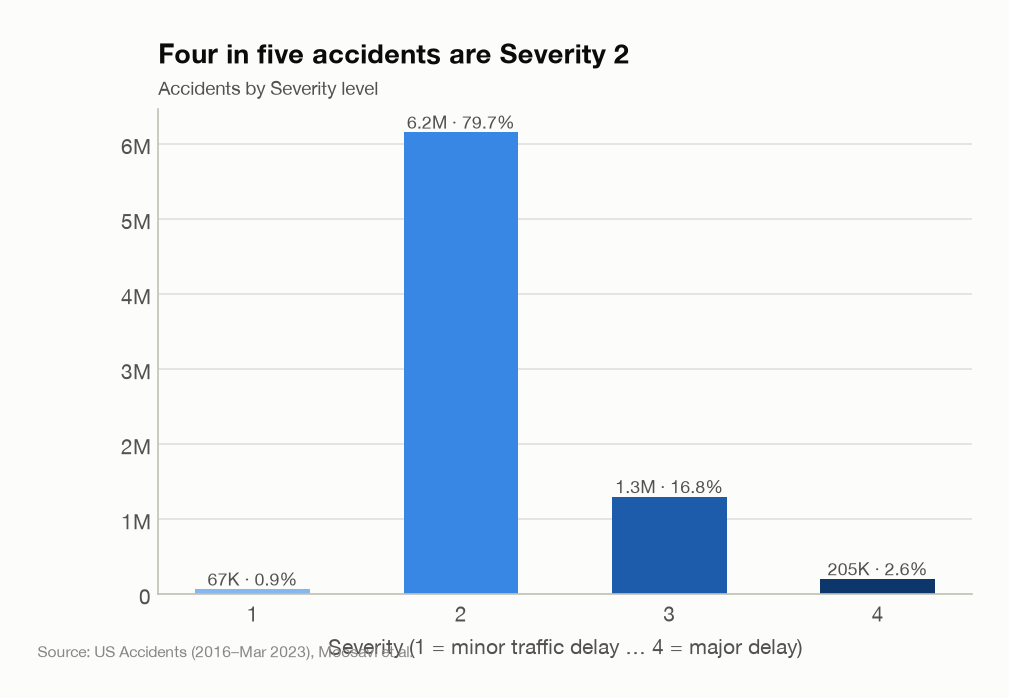

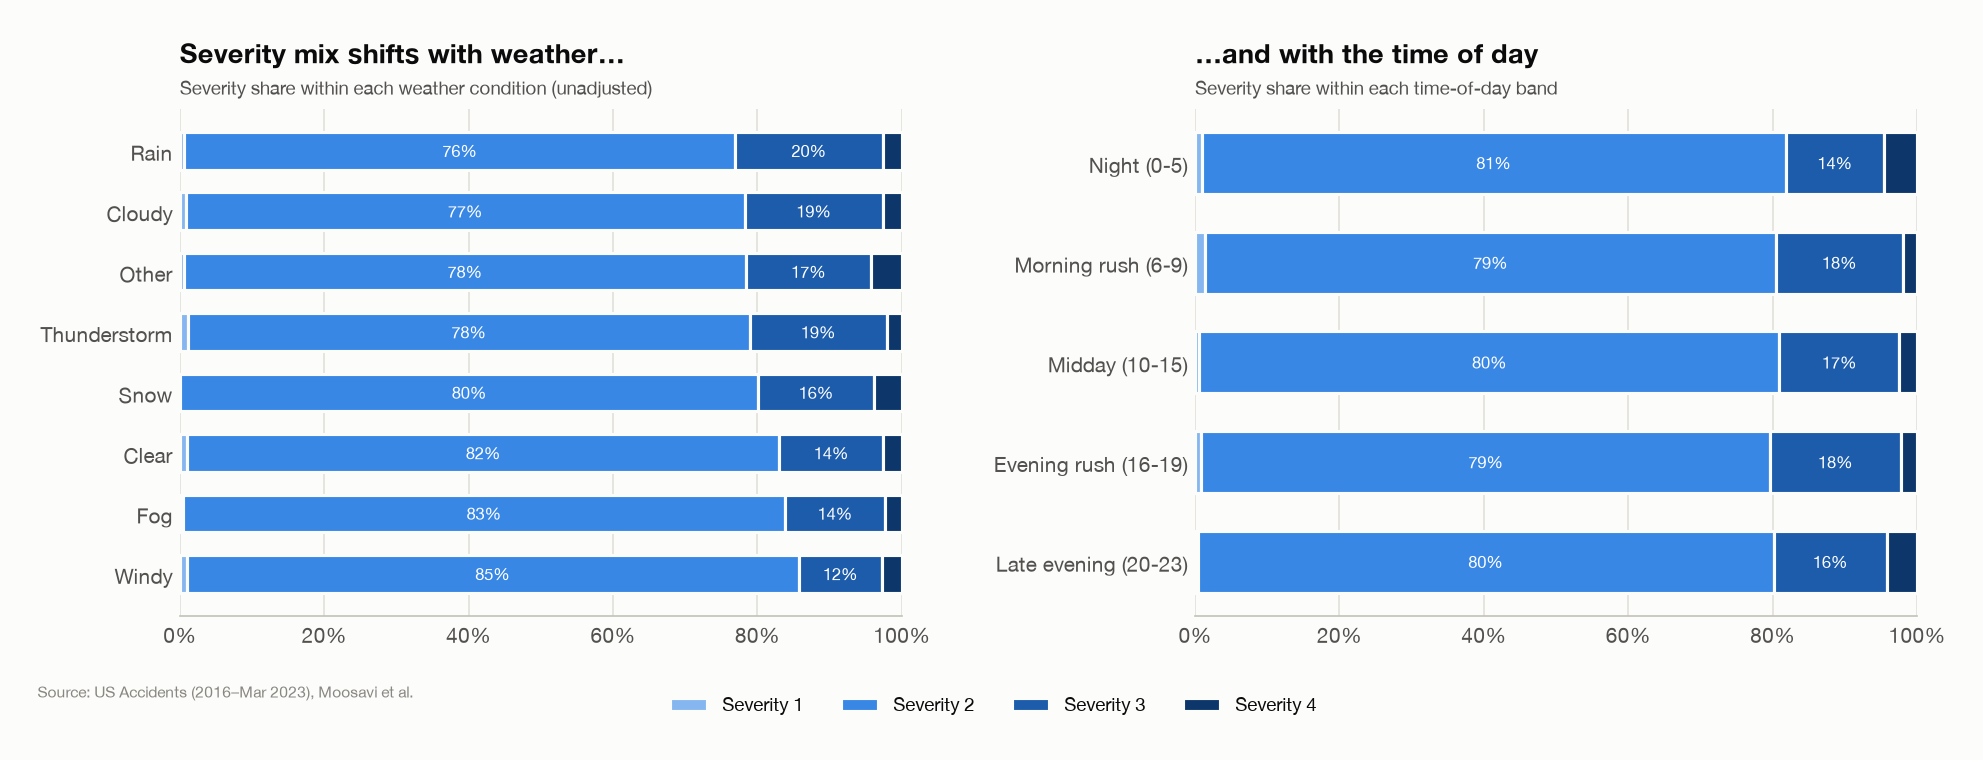

In [18]:
show(viz.plot_day_night(tables["day_night"], tables["severity_by_day_night"]), width=1000)
show(viz.plot_severity_distribution(tables["severity_distribution"]), width=600)
show(viz.plot_severity_shift(tables["severity_by_weather"], tables["severity_by_time_of_day"]), width=1000)

**Takeaways**
- **Traffic signals (15%), crossings (11%) and junctions (7%)** are the most common accident locations.
- **Controlled spots produce milder accidents.** Year-adjusted, signals, crossings, stops and stations are **12–15 points less often severe**: frequent, low-speed fender-benders.
- **Junctions are the exception (+6 pts).** In this data a "junction" is often a highway exit, where merging traffic meets speed.
- **Road type is the sharpest split.** Interstates carry 25% of accidents, and those are severe far more often than on local roads.
- **Day vs night:** two-thirds of accidents happen in daylight, and the Severity ≥ 3 share is about equal. But **Severity 4 is more common at night (3.5% vs 2.3%)**.

## 6 · Where: states, cities and hotspots

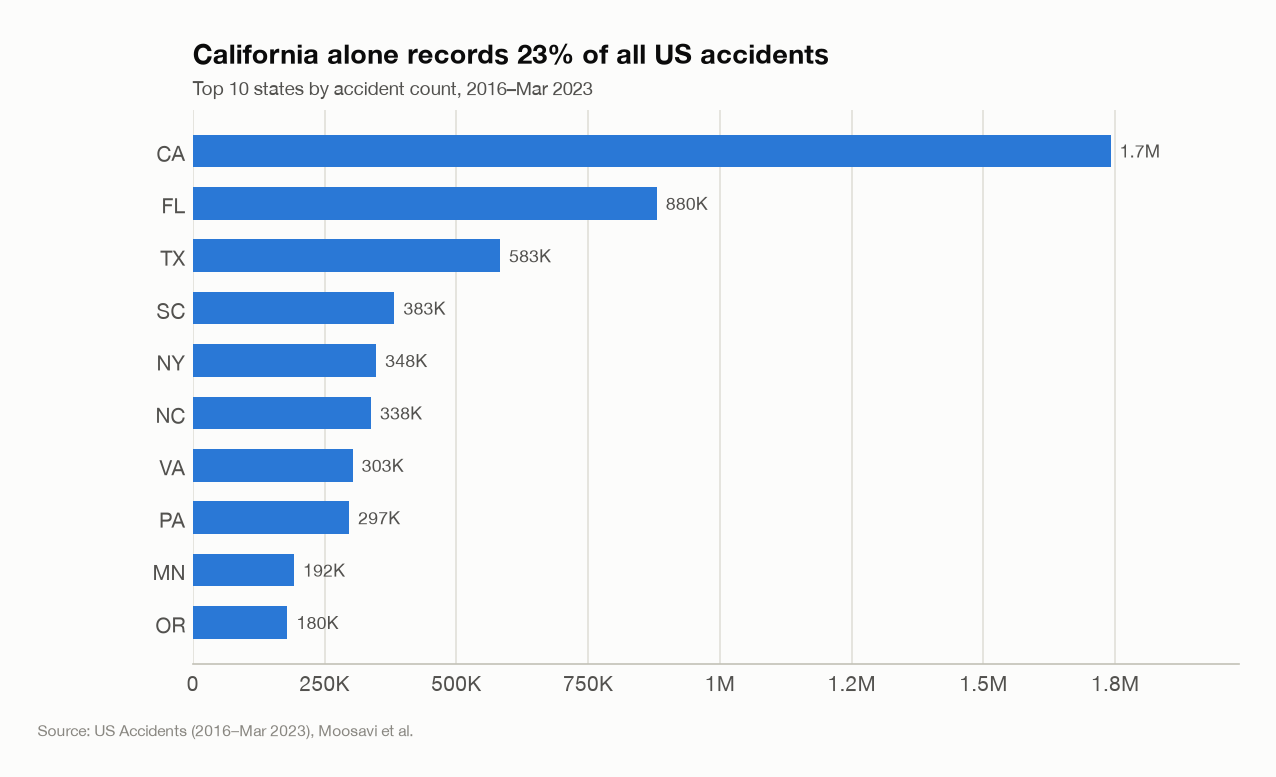

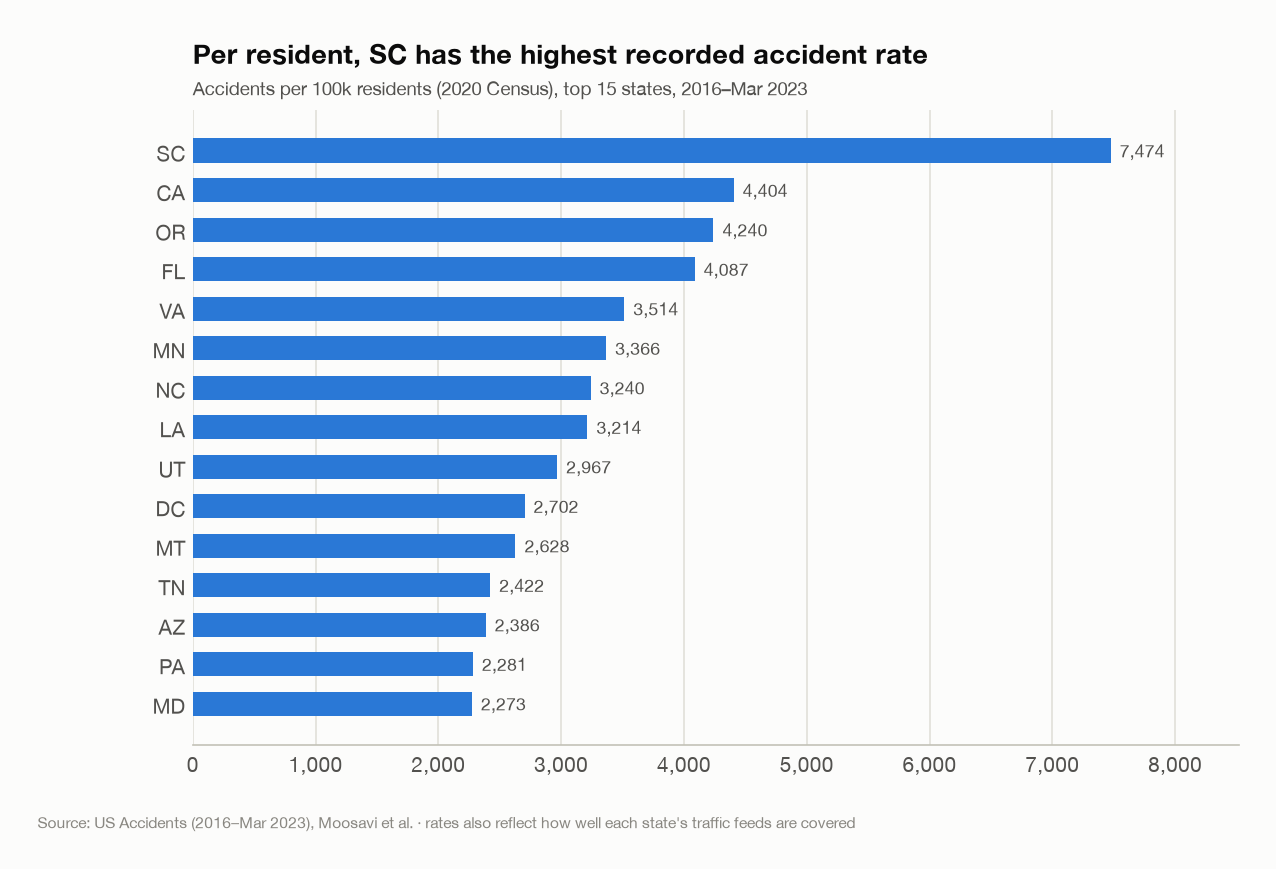

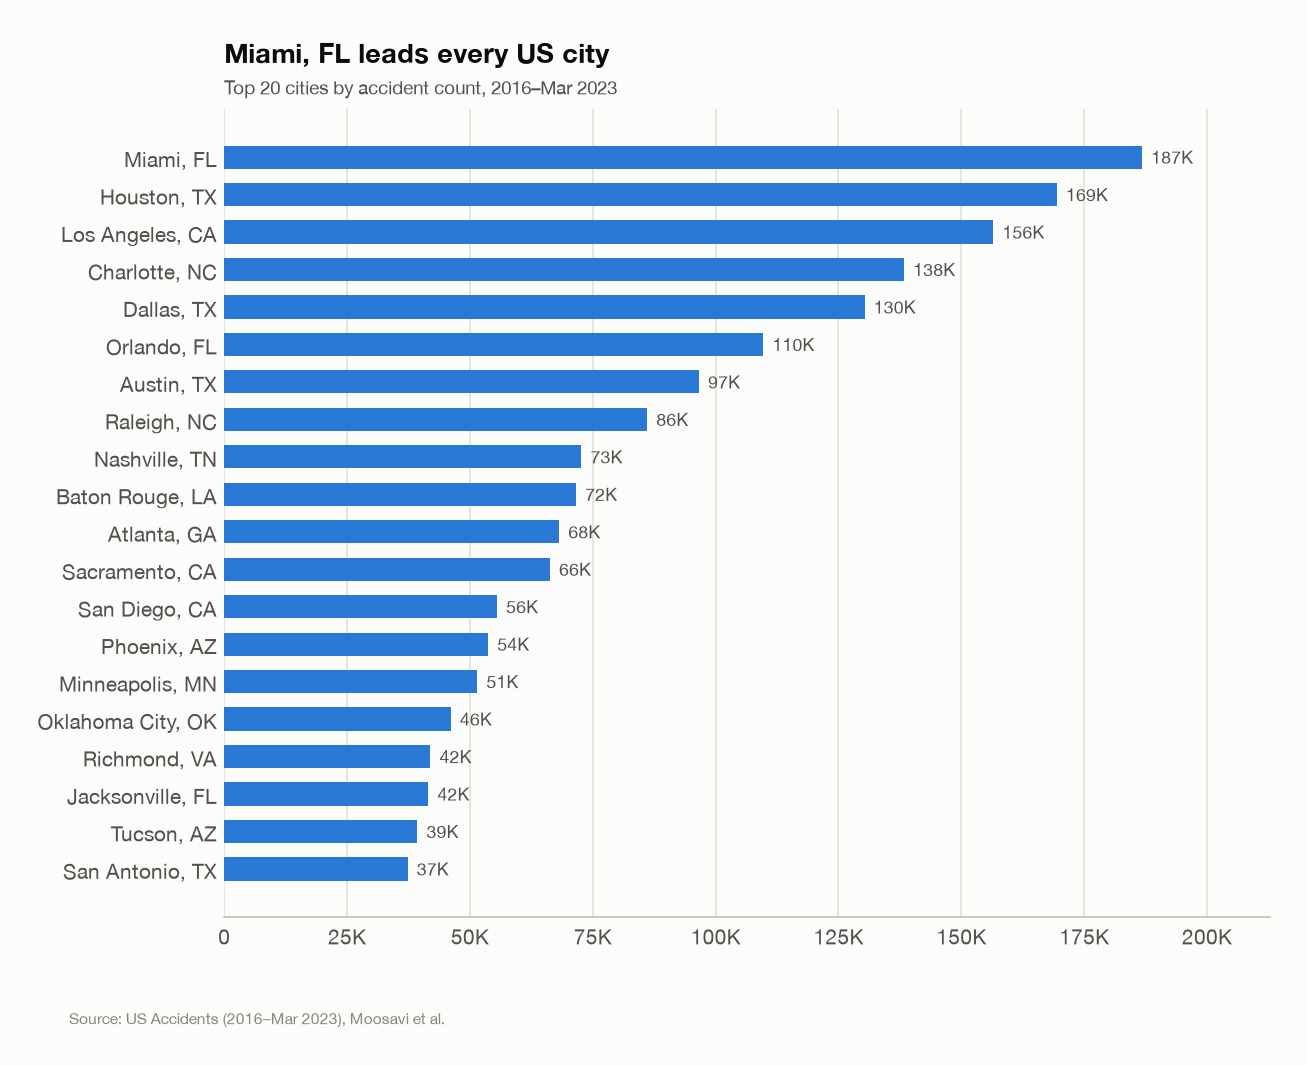

In [19]:
show(viz.plot_top_states(tables["top_states"]), width=750)
show(viz.plot_state_per_capita(tables["state_per_capita"]), width=750)
show(viz.plot_top_cities(tables["top_cities"]), width=750)

California has **22.5%** of all recorded accidents, and **Miami** tops every city. Per resident, **South Carolina** stands out at about 7,500 accidents per 100k over the period. Per-capita rates also reflect how well each state's traffic feeds are covered, so treat them as *recorded* rates.

### Hotspots: ~1 km grid binning

Every accident is snapped to a 0.01° (~1 km) grid. Counting cells across all 7.7M points is a single vectorised group-by; DBSCAN would be far too slow and memory-hungry at this scale. Greedy non-maximum suppression keeps the 20 densest *distinct* cells.

In [20]:
top20 = hotspots.top_hotspots(df, n=20)
top20[["rank", "label", "count", "avg_severity", "high_severity_pct", "peak_hour", "junction_pct"]]

,rank,label,count,avg_severity,high_severity_pct,peak_hour,junction_pct
0,1,"I-605 S · Downey, CA",3704,2.55,54.54,13,9.4
1,2,"Alexander Hamilton Bridge · Bronx, NY",3144,2.43,42.08,14,17.9
2,3,"CA-110 S · Los Angeles, CA",3106,2.42,40.86,14,21.4
3,4,"NE 125th St · North Miami, FL",3105,2.00,0.06,15,0.0
4,5,"International Dr · Orlando, FL",3094,2.01,1.39,19,1.1
5,6,"I-95 N · Fort Lee, NJ",2996,2.39,38.18,7,22.7
6,7,"I-95 N · Miami, FL",2968,2.56,53.94,13,6.6
7,8,"W Flagler St · Miami, FL",2925,2.00,0.10,16,0.0
8,9,"SW 137th Ave · Miami, FL",2877,2.00,0.03,13,0.0
9,10,"S Orange Blossom Trl · Orlando, FL",2827,2.01,0.64,15,0.0


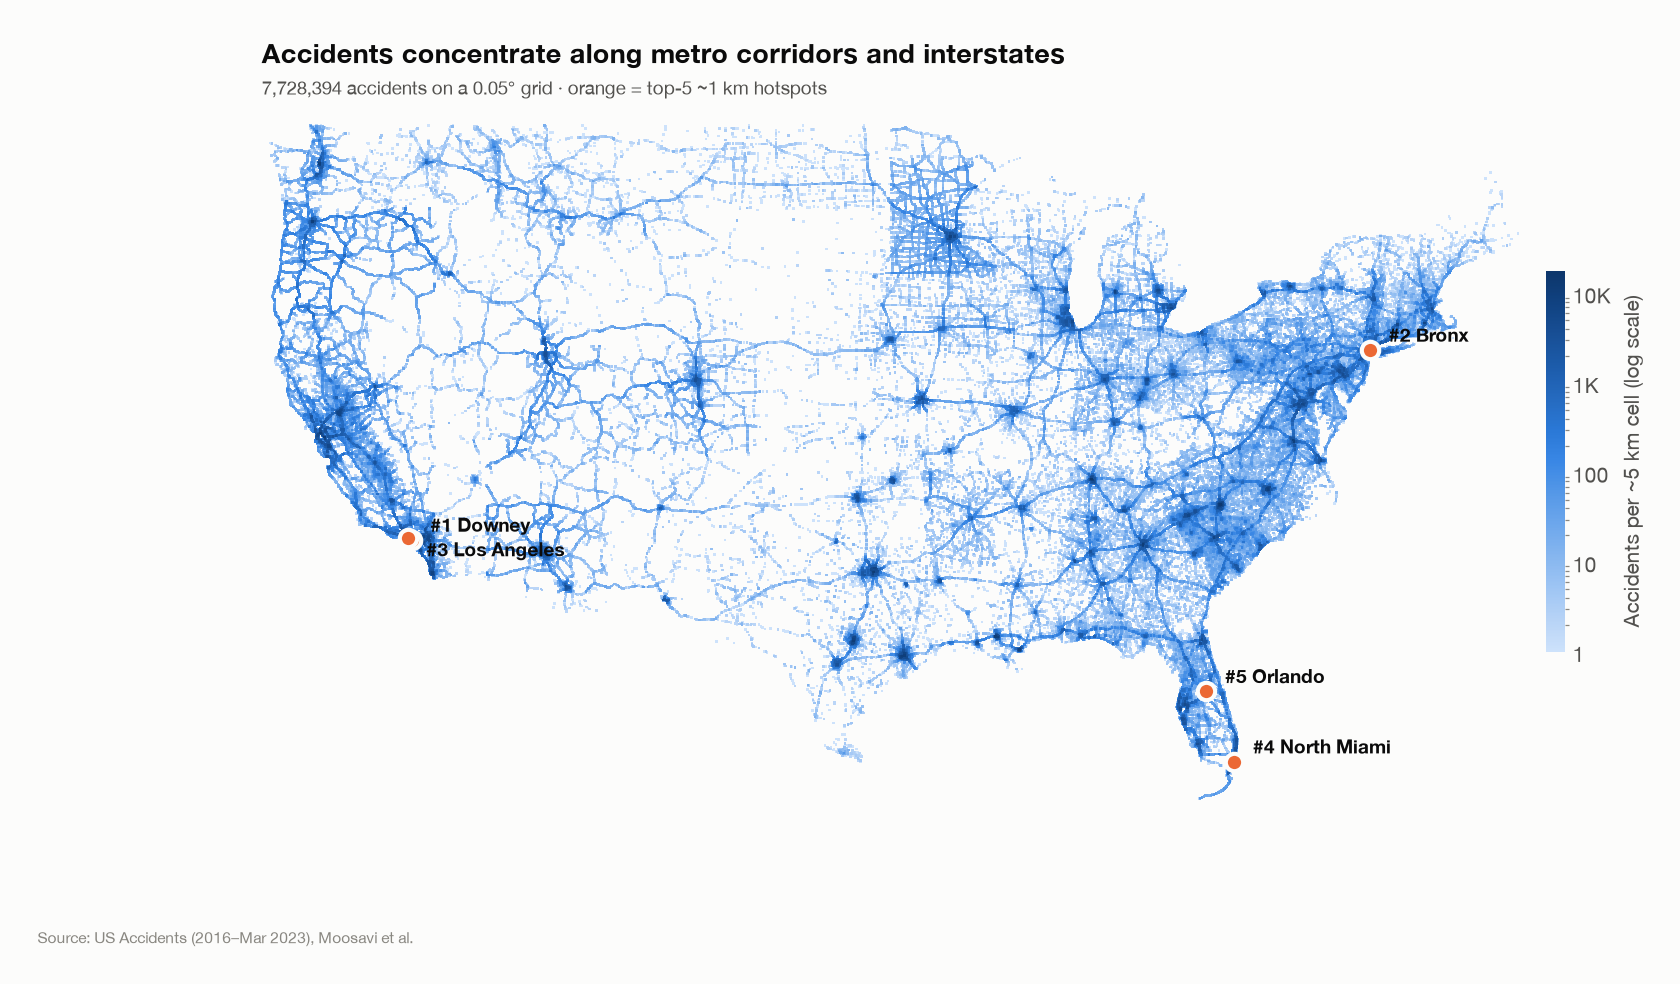

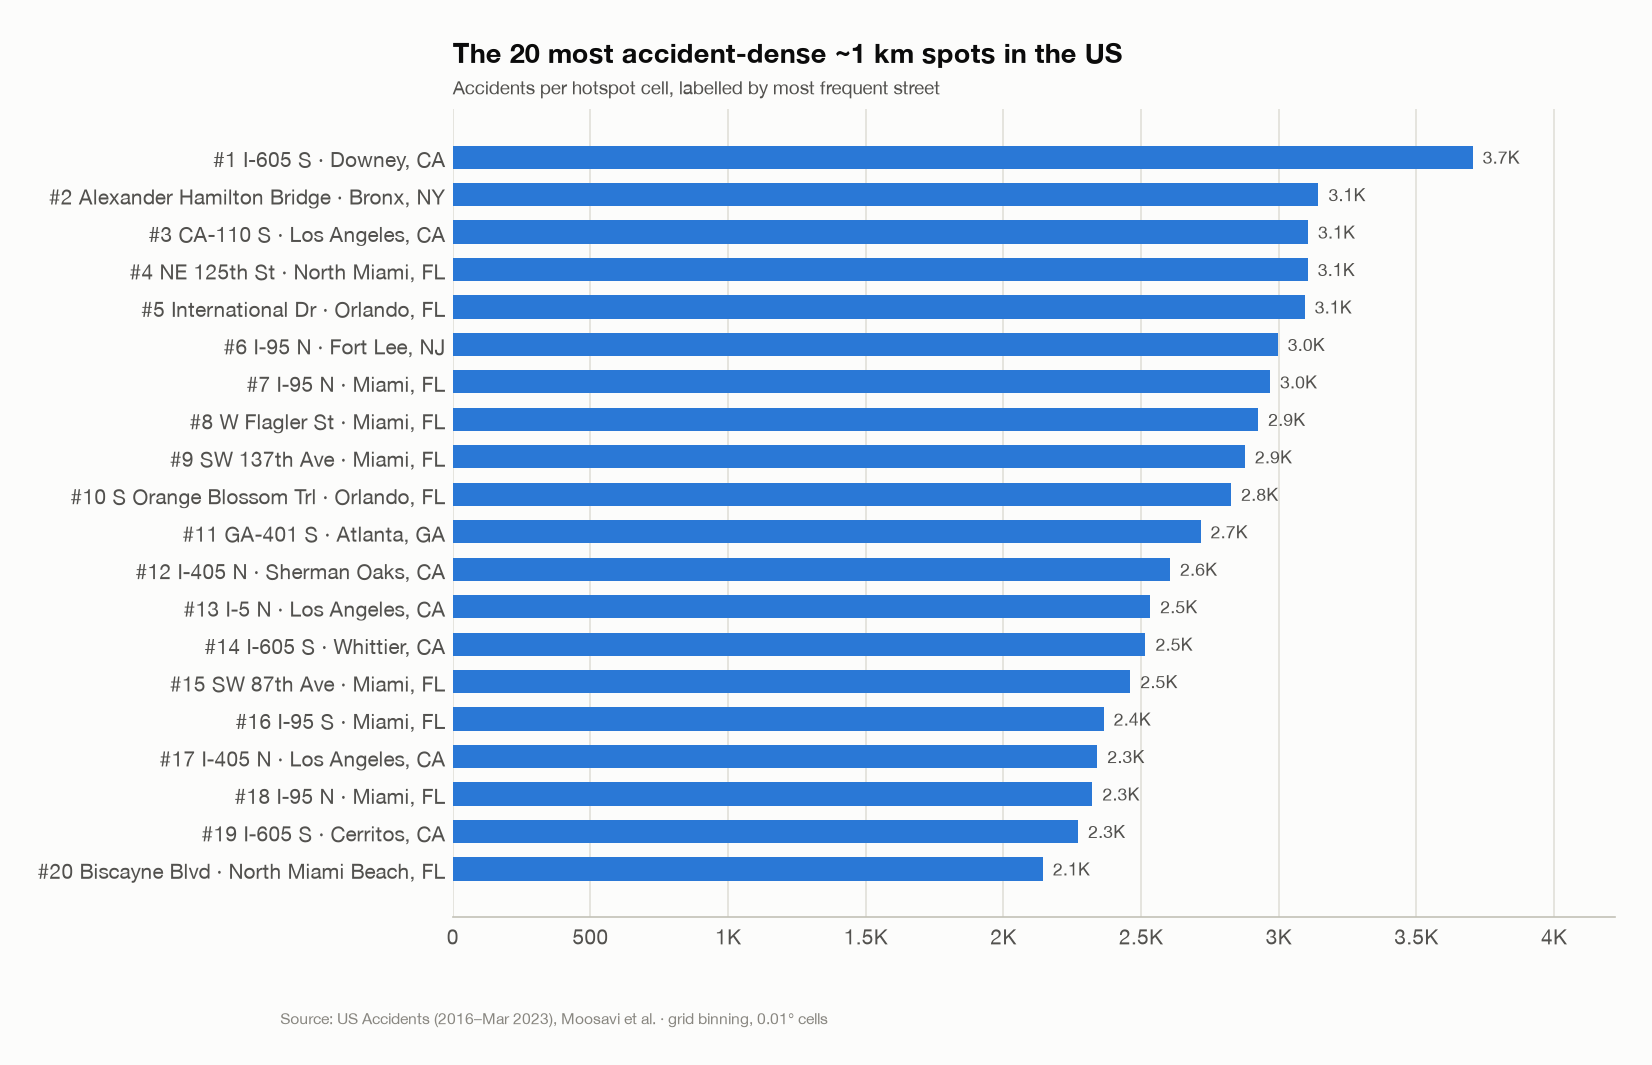

In [21]:
show(hotspots.plot_us_density(df, top20), width=1000)
show(hotspots.plot_top_hotspots(top20), width=800)

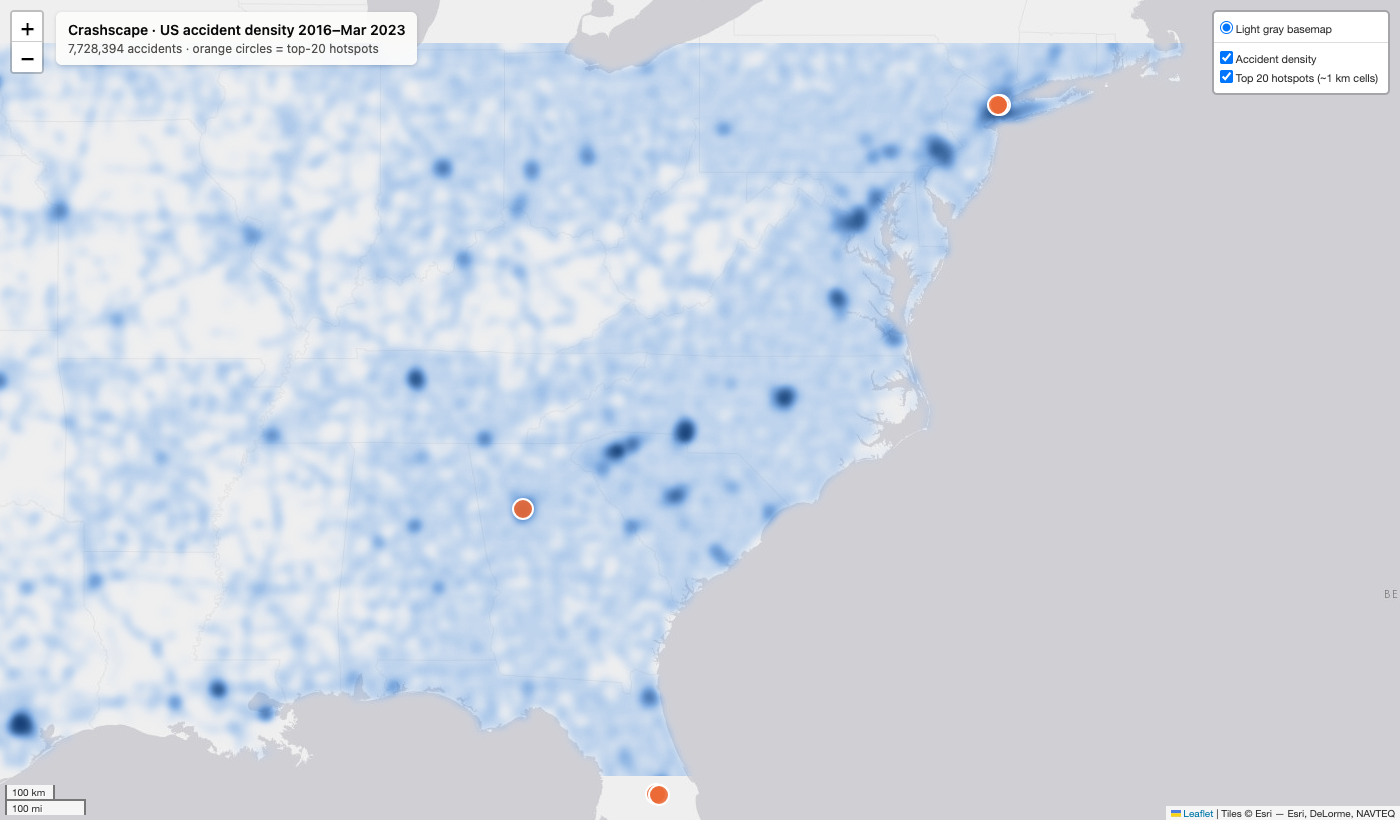

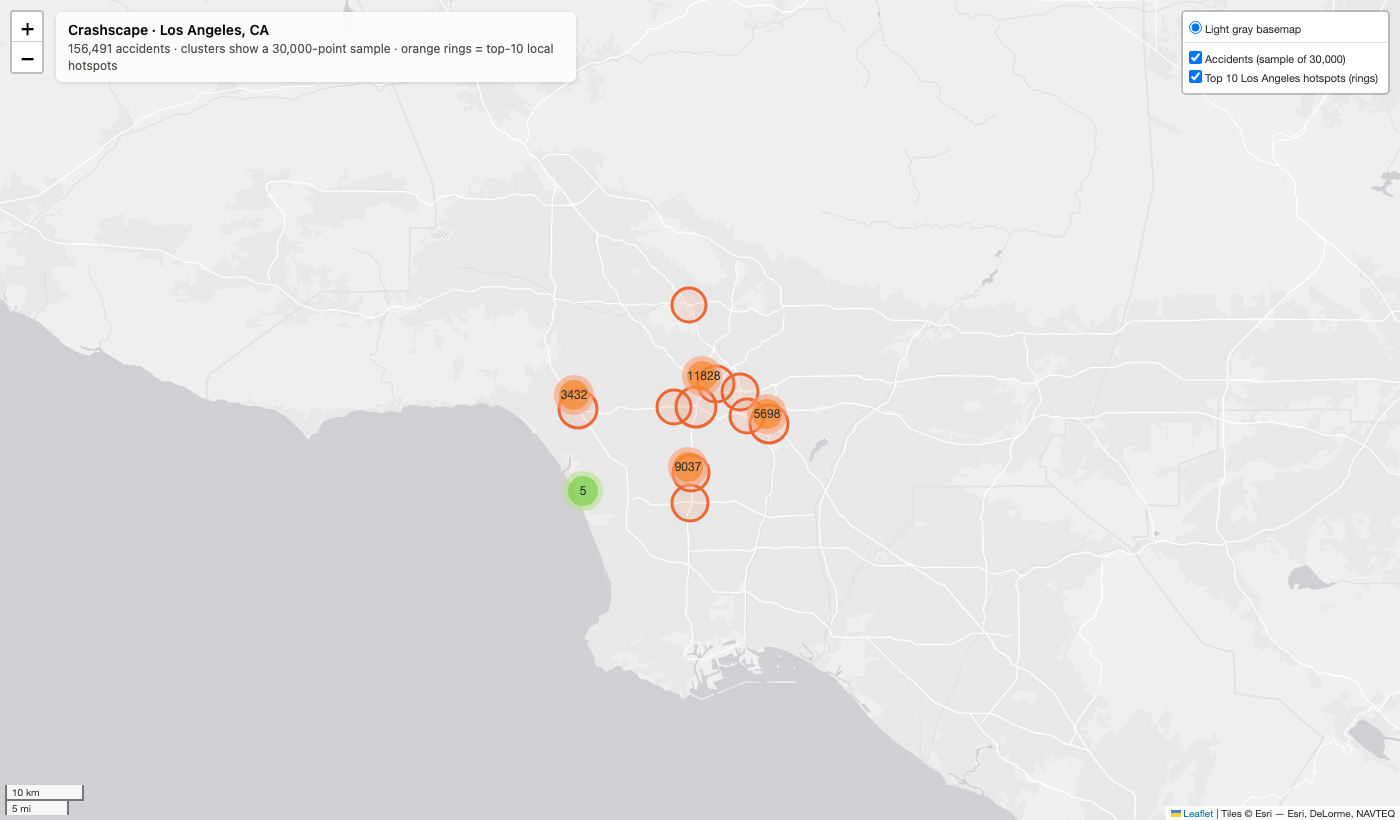

In [22]:
# Interactive maps (open in a browser): reports/maps/hotspot_heatmap.html, la_cluster_map.html,
# hotspot_density_plotly.html. Screenshots:
show(ROOT / "reports/screenshots/map_heatmap_east.png", width=900)
show(ROOT / "reports/screenshots/map_la_clusters.png", width=900)

**Takeaways**
- The #1 hotspot is **I-605 S in Downey, CA**: about 3,700 accidents in roughly 1 km. It's followed by the **Alexander Hamilton Bridge (I-95, Bronx)**, **CA-110 in Los Angeles** and several Miami and Orlando arterials.
- **Freeway hotspots are 23–68% severe** (most above 38%). Florida surface-street hotspots are close to **0%** severe, almost always labelled Severity 2. That looks like a reporting-source habit, not genuinely safer roads: another face of the reporting drift.

## 7 · Contributing factors: what predicts a severe accident?

`src/factors.py` trains a **HistGradientBoostingClassifier** (LightGBM-style GBDT) on the 500k sample to predict Severity ≥ 3, plus a RandomForest baseline.
- **No leakage:** `Distance(mi)` and `duration_min` are measured *after* the crash, so they're excluded.
- **Year and state are kept as controls** for reporting drift.
- **SHAP** (TreeExplainer, 5k test rows) attributes each prediction to its features. One-hot columns are summed back to their original feature.

Results are loaded from `reports/tables/`. Re-train with `python -m src.factors`, which takes about 3 minutes.

In [23]:
metrics = json.loads((config.TABLES_DIR / "model_metrics.json").read_text())
pd.DataFrame({k: metrics[k] for k in ("hgb", "hgb_conditions_only", "random_forest")}).T[
    ["roc_auc", "pr_auc", "precision", "recall", "f1"]].round(3)

,roc_auc,pr_auc,precision,recall,f1
hgb,0.86,0.63,0.46,0.77,0.57
hgb_conditions_only,0.78,0.51,0.37,0.71,0.49
random_forest,0.84,0.59,0.46,0.74,0.56


In [24]:
imp = pd.read_csv(config.TABLES_DIR / "factor_importance.csv")
display(imp.groupby("family")["share_pct"].sum().sort_values(ascending=False).round(1).to_frame("share of |SHAP| %"))
imp.head(12)[["label", "family", "share_pct", "direction"]]

,share of |SHAP| %
family,
Reporting context,47.1
Road,30.4
Time,14.4
Weather,8.0


,label,family,share_pct,direction
0,Year,Reporting context,29.69,"highest risk at 2017–2018, lowest at 2022–2023"
1,Road type,Road,17.70,raises risk most for Interstate; lowers it mos...
2,State,Reporting context,17.45,"raises risk most for IL, GA, CO; lowers it mos..."
3,Month,Time,8.13,"highest risk at 5–7, lowest at 11–12"
4,No. of road features,Road,3.81,"highest risk at 0–1, lowest at 1–2"
5,Hour of day,Time,3.26,"highest risk at 17–19, lowest at 7–8"
6,Crossing,Road,3.24,lowers risk when present (-0.43 log-odds)
7,Day of week,Time,2.44,"highest risk at 5–6, lowest at 2–3"
8,Air pressure,Weather,2.12,"highest risk at 30.16–30.7, lowest at 25.01–28.89"
9,Traffic Signal,Road,2.02,lowers risk when present (-0.19 log-odds)


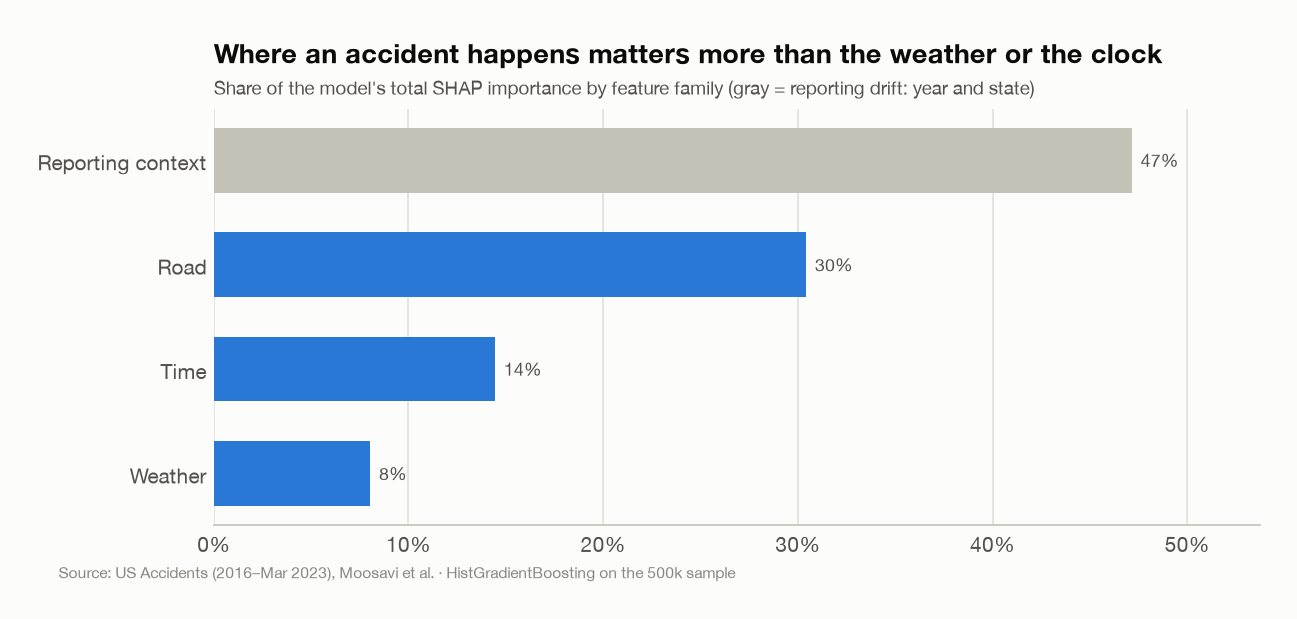

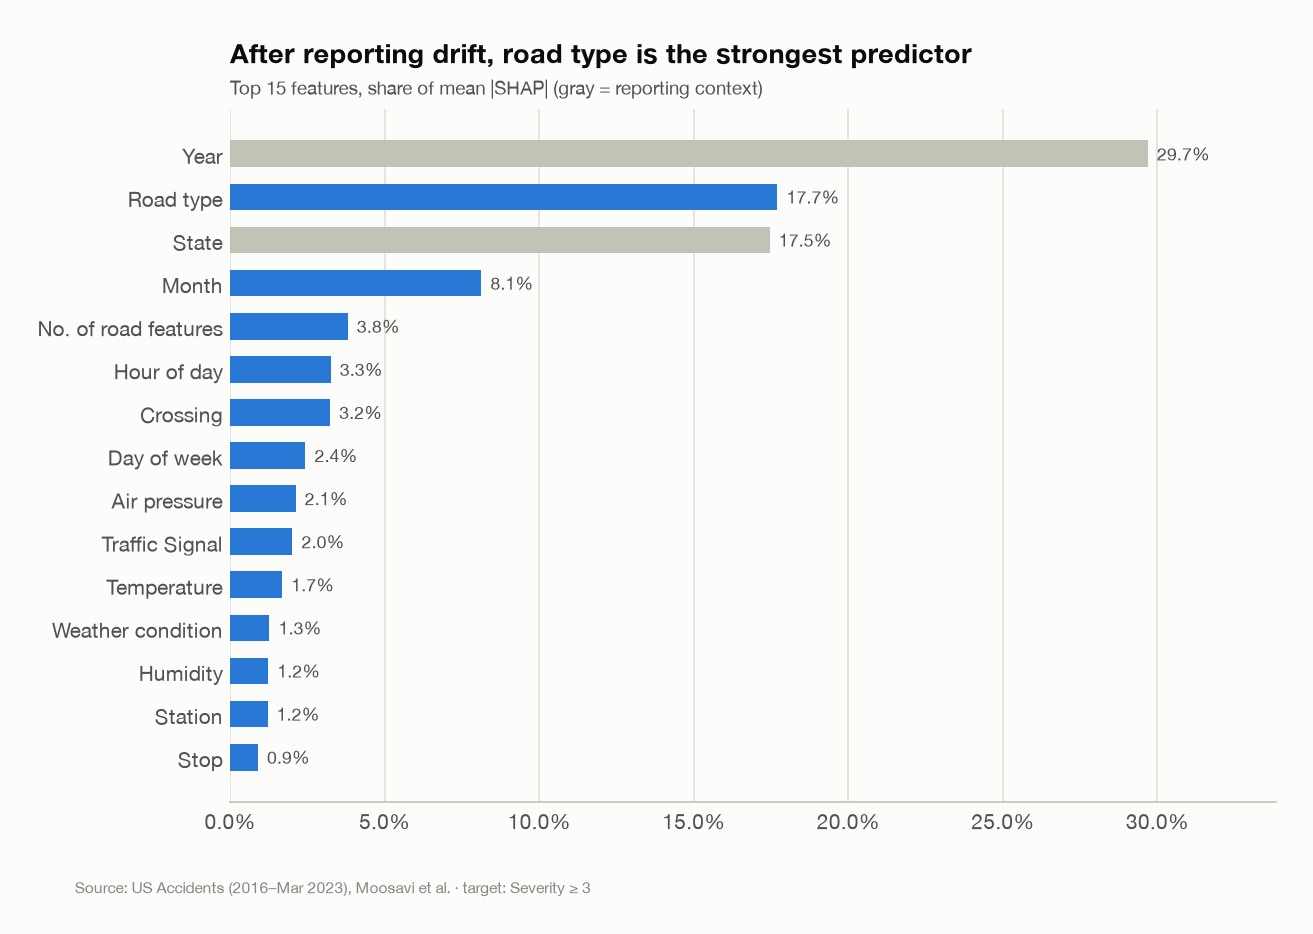

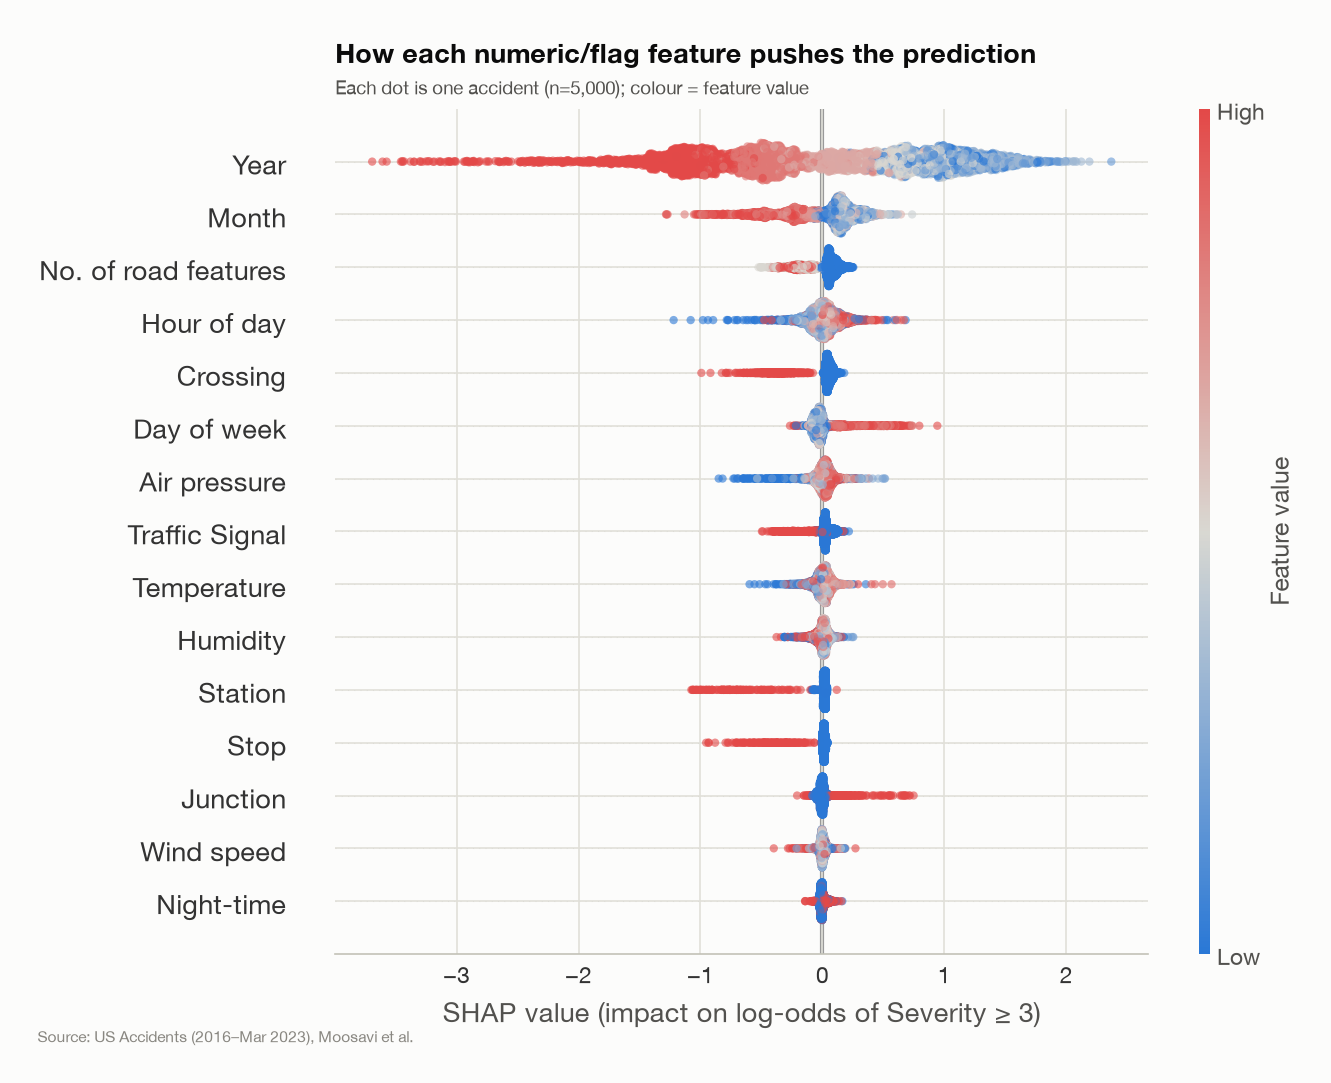

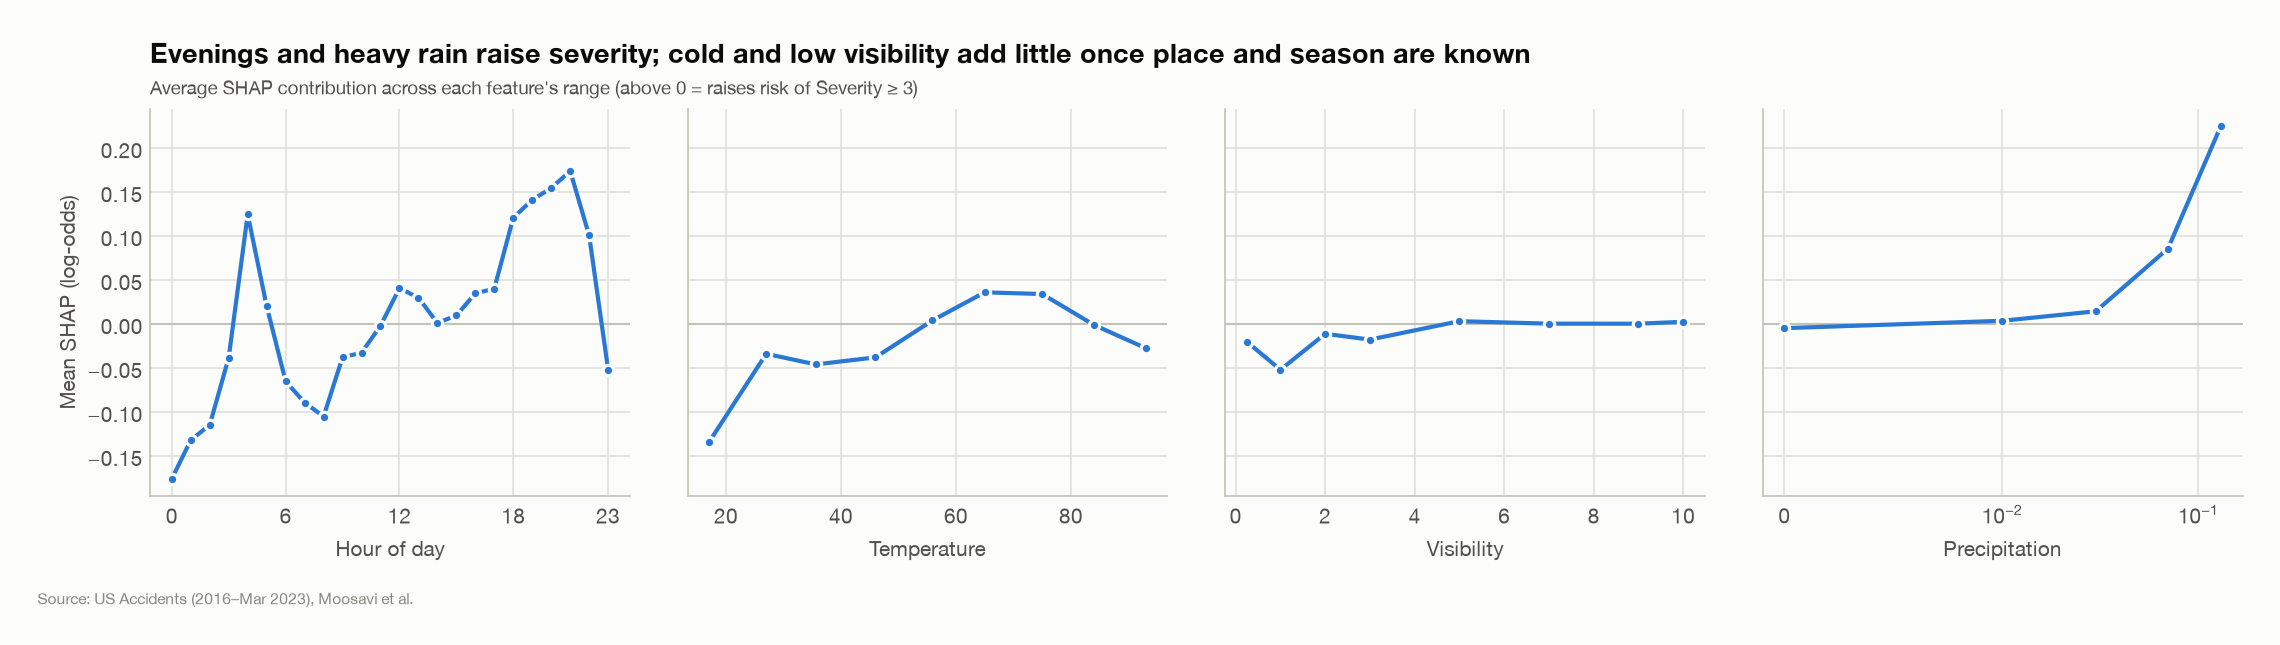

In [25]:
for name in ("19_factor_families", "20_top_factors", "21_shap_summary", "22_shap_dependence"):
    show(FIGURES / f"{name}.png", width=1000 if name == "22_shap_dependence" else 800)

In [26]:
levels = pd.read_csv(config.TABLES_DIR / "factor_level_effects.csv")
levels[levels["group"].isin(["road_type", "time_of_day", "precipitation", "day_of_week", "temperature"])].round(2)

,group,level,n,mean_shap,odds_x
0,road_type,Interstate,1216,0.92,2.50
1,road_type,Highway,1380,-0.11,0.90
2,road_type,Local road,2404,-0.52,0.60
18,day_of_week,Monday,725,-0.03,0.98
19,day_of_week,Tuesday,879,-0.03,0.97
20,day_of_week,Wednesday,839,-0.03,0.97
21,day_of_week,Thursday,845,-0.04,0.96
22,day_of_week,Friday,909,-0.03,0.97
23,day_of_week,Saturday,439,0.22,1.25
24,day_of_week,Sunday,364,0.23,1.25


In [27]:
# The auto-generated plain-English explanation
text = (ROOT / "reports/factors_explained.md").read_text()
display(Markdown(text[text.index("## In plain English"):]))

## In plain English

Odds multipliers below are exp(mean SHAP) for that level: how much it multiplies the odds of a Severity ≥ 3 accident relative to the model's average prediction.

1. **Road type is the biggest real-world factor.** On an interstate the odds of a severe accident are ×2.50 the average; on a local road ×0.60. Highway crashes block lanes for longer, and lane blockage is exactly what Severity measures.
2. **Controlled, slow-speed spots produce milder accidents.** Station, Amenity, Stop, Crossing all push the odds *down* (e.g. crossing ×0.69, traffic signal ×0.86). These are frequent fender-benders at low speed.
3. **Junctions are the exception** (×1.11). In this data a junction is often a highway exit, where merging traffic meets higher speeds.
4. **Time of day is non-linear.** Odds are highest in the late evening (20-23) (1.12×) and lowest in the morning rush (6-9) (0.92×): rush hour brings *many* minor crashes, while evening crashes are fewer but more serious.
5. **Weekends are worse per accident.** Saturday ×1.25 and Sunday ×1.25 vs Wednesday ×0.97.
6. **Heavy rain matters, light rain barely.** Precipitation above 0.05 in/hr: ×1.21; light: ×1.01. Weather condition ranks highest for Rain, Thunderstorm and lowest for Snow, Clear.
7. **Cold and low visibility add little on their own.** Below freezing: ×0.93; visibility carries only 0.4% of the model's importance. Raw data shows more severe crashes in the cold, but the model attributes that to *where and when* it's cold (northern states, winter months), not the temperature itself.
8. **Caveat: reporting drift.** Year and State account for 47% of the model's attributions. Severity labelling changed across years and data sources, so these are controls rather than real-world risk factors. Weather/road/time effects above are estimated *net* of them.


**Takeaways**
- The model separates severe from non-severe accidents well: **ROC-AUC 0.858**, against a 0.840 RandomForest baseline.
- Even **without year and state** it reaches **0.784**, so road, weather and time carry real signal on their own.
- **Where an accident happens matters more than when, and far more than the weather.** Road features take ~30% of total importance, time ~14% and weather ~8%; reporting drift (year, state) takes the remaining ~47%.
- The model **overturns a raw-data intuition: cold itself is not the danger.** Sub-freezing readings look worse in raw tables, but once state and month are known, the cold reading adds nothing (×0.93). Heavy rain keeps a real effect (×1.21).

## 8 · Key Findings & Safety Recommendations

**Key findings**
1. **Accidents follow the commute.** Weekday peaks are 7–8 AM (8.4% of weekday crashes) and 4–5 PM. Weekends peak at 2 PM with about half the volume.
2. **Interstates are where crashes turn severe.** About a quarter of accidents happen on interstates, where the odds of a severe outcome are **×2.5** the average, versus ×0.6 on local roads. Every top-20 hotspot with a high severe share is on a freeway (I-605, I-95, CA-110, I-405, GA-401).
3. **Intersections with control devices see many crashes but mild ones.** Signals, crossings and stops are 12–15 points less often severe. **Highway junctions/exits are the exception (+6 pts).**
4. **Bad weather is rare but raises severity.** 84% of crashes happen in clear or cloudy conditions. But thunderstorms (25%), snow (24%) and rain (23%) beat clear (18%) on severe share, and **heavy rain lifts the odds ×1.21**.
5. **Evenings and weekends bring fewer but worse crashes.** Late evening (8 PM–midnight) is the most severe time band, Severity 4 is more common at night (3.5% vs 2.3%), and weekend accidents carry **×1.25** odds of being severe.

**Safety recommendations**

6. **Prioritise interstate interchanges for engineering fixes.** Ramp metering, longer merge lanes and better signage at exits, starting with the top-20 freeway hotspots (I-605 Downey/Whittier/Cerritos, Alexander Hamilton Bridge, CA-110, I-405).
7. **Clear incidents faster on freeways.** Severity here *is* traffic impact, so quick-clearance policies, freeway service patrols and pre-positioned tow trucks at hotspot corridors reduce severity directly.
8. **Run weather-responsive operations.** Trigger variable speed limits, dynamic message signs and staged response crews from heavy-rain and storm forecasts, rather than reacting after the first crash.
9. **Focus evening and weekend enforcement and lighting.** Impaired- and speed-driving enforcement from 8 PM to midnight and on weekends, plus lighting audits on high-speed corridors where night crashes skew to Severity 4.
10. **Fix the data, too.** Severity labelling drifted with data sources (35% → 7% severe), and one region's surface streets are almost never labelled severe. Agencies sharing crash feeds should standardise severity definitions so risk can be compared across years and states.

---
*Data citation:* Moosavi, S., Samavatian, M. H., Parthasarathy, S., & Ramnath, R. (2019). *A Countrywide Traffic Accident Dataset.* arXiv:1906.05409. · Moosavi, S., Samavatian, M. H., Parthasarathy, S., Teodorescu, R., & Ramnath, R. (2019). *Accident Risk Prediction based on Heterogeneous Sparse Data: New Dataset and Insights.* ACM SIGSPATIAL 2019.